# 🍿 Netflix User Watching Behavior — Exploratory Data Analysis

**Goal:** understand *who* our subscribers are, *how* they watch, and — above all — *why they leave*, then turn those findings into concrete retention recommendations.

**Dataset:** 50,000 users × 20 behavioural / demographic features (`data/netflix_user_behavior.csv`).

> ⚠️ **Data note.** The dataset in this repository is a *simulated* file generated by `src/generate_dataset.py` with the exact schema from the brief. To analyse the original file, replace `data/netflix_user_behavior.csv` and re-run this notebook (all figures in the narrative are computed live from the data).

### How this notebook is organised
| # | Section | Business question it answers |
|---|---|---|
| 1 | Data understanding & quality | Can we trust the data? |
| 2 | Feature engineering | What extra signals can we derive? |
| 3 | Univariate analysis | What does the base look like? |
| 4 | Bivariate analysis | What drives churn & engagement? |
| 5 | Multivariate analysis | Which segments are most (and least) at risk? |
| 6 | Tenure / cohort analysis | *When* in the lifecycle do users leave? |
| 7 | Statistical testing | Are the patterns real or noise? |
| 8 | Business recommendations | What should the business do, and what is it worth? |

## 0. Setup

In [ ]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

# ---- Global style: Netflix-inspired palette so every chart is consistent ----
RED, DARK, GREY, LIGHT = "#E50914", "#221F1F", "#8C8C8C", "#E8E8E8"
PALETTE = [RED, "#B20710", "#F5A3A8", GREY, DARK, "#4C4C4C"]
sns.set_theme(style="whitegrid", context="notebook", palette=PALETTE)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.spines.top": False,
                     "axes.spines.right": False})

DATA_PATH = "../data/netflix_user_behavior.csv"
IMG_DIR = "../images"
os.makedirs(IMG_DIR, exist_ok=True)

M = {}   # dictionary of headline metrics -> exported to JSON for the README / slide deck


def savefig(name):
    """Tidy layout and save the current figure for the presentation."""
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}.png", dpi=150, bbox_inches="tight")


def pct(x, d=1):
    """Format a proportion as a percentage string."""
    return f"{x * 100:.{d}f}%"


def wilson_ci(successes, n, z=1.96):
    """95% Wilson confidence interval for a proportion (robust for small groups)."""
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

## 1. Data Understanding & Quality Checks

Before any analysis we verify the structure, types, missing values, duplicates and plausible ranges. Bad data silently produces confident-looking but wrong insights.

In [ ]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 50,000 | Columns: 20


,user_id,age,gender,country,account_age_months,subscription_type,monthly_fee,payment_method,primary_device,devices_used,favorite_genre,avg_watch_time_minutes,watch_sessions_per_week,binge_watch_sessions,completion_rate,rating_given,content_interactions,recommendation_click_rate,days_since_last_login,churned
0,U100000,39,Male,Mexico,3,Basic,6.47,Credit Card,Smart TV,3,Thriller,89.2,3,3,57.9,4.0,9,14.9,2,0
1,U100001,23,Female,India,72,Basic,4.94,Credit Card,Laptop,5,Animation,55.0,4,1,55.9,3.6,5,24.9,32,1
2,U100002,44,Female,Canada,8,Standard,13.71,Debit Card,Smart TV,4,Thriller,131.5,6,5,67.3,3.7,7,10.9,5,0
3,U100003,46,Female,India,2,Basic,4.94,Debit Card,Smart TV,4,Romance,153.8,3,6,78.5,3.9,13,24.9,5,0
4,U100004,18,Male,USA,34,Premium,17.99,Credit Card,Tablet,6,Horror,58.5,5,1,53.0,3.6,9,10.6,1,0


In [ ]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   user_id                    50000 non-null  str    
 1   age                        50000 non-null  int64  
 2   gender                     50000 non-null  str    
 3   country                    50000 non-null  str    
 4   account_age_months         50000 non-null  int64  
 5   subscription_type          50000 non-null  str    
 6   monthly_fee                50000 non-null  float64
 7   payment_method             50000 non-null  str    
 8   primary_device             50000 non-null  str    
 9   devices_used               50000 non-null  int64  
 10  favorite_genre             50000 non-null  str    
 11  avg_watch_time_minutes     50000 non-null  float64
 12  watch_sessions_per_week    50000 non-null  int64  
 13  binge_watch_sessions       50000 non-null  int64  
 14  c

In [ ]:
# Quality checks: missing values, duplicate users, impossible values
checks = {
    "Missing values (total)": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate user_ids": int(df["user_id"].duplicated().sum()),
    "Age outside 13-100": int((~df["age"].between(13, 100)).sum()),
    "Completion rate outside 0-100": int((~df["completion_rate"].between(0, 100)).sum()),
    "Rating outside 1-5": int((~df["rating_given"].between(1, 5)).sum()),
    "Negative days since login": int((df["days_since_last_login"] < 0).sum()),
    "Account age < 1 month": int((df["account_age_months"] < 1).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
Missing values (total),0
Duplicate rows,0
Duplicate user_ids,0
Age outside 13-100,0
Completion rate outside 0-100,0
Rating outside 1-5,0
Negative days since login,0
Account age < 1 month,0


In [ ]:
# Summary statistics for numeric columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,50000.0,35.42,11.22,18.00,27.00,35.00,43.00,75.00
account_age_months,50000.0,23.57,17.38,1.00,10.00,19.00,33.00,72.00
monthly_fee,50000.0,11.48,4.10,4.94,8.54,12.59,13.99,17.99
devices_used,50000.0,3.45,1.61,1.00,2.00,3.00,4.00,7.00
avg_watch_time_minutes,50000.0,80.14,47.59,6.30,47.30,69.00,100.70,480.00
watch_sessions_per_week,50000.0,4.57,2.30,1.00,3.00,4.00,6.00,19.00
binge_watch_sessions,50000.0,2.94,2.14,0.00,1.00,3.00,4.00,18.00
completion_rate,50000.0,59.65,13.13,5.00,50.80,59.70,68.60,100.00
rating_given,50000.0,3.47,0.53,1.30,3.10,3.50,3.80,5.00
content_interactions,50000.0,9.30,4.99,0.00,6.00,8.00,12.00,51.00


In [ ]:
# Categorical overview: number of levels and the most common level
cat_cols = df.select_dtypes(include="object").columns.drop("user_id")
pd.DataFrame({"unique_levels": df[cat_cols].nunique(),
              "most_common": df[cat_cols].mode().iloc[0],
              "most_common_share": [pct(df[c].value_counts(normalize=True).iloc[0]) for c in cat_cols]})

,unique_levels,most_common,most_common_share
gender,3,Female,48.1%
country,10,USA,24.1%
subscription_type,3,Standard,42.0%
payment_method,4,Credit Card,45.1%
primary_device,5,Smart TV,38.2%
favorite_genre,10,Comedy,15.0%


**What we learn**

* The data is **clean**: no missing values, no duplicate users and no out-of-range values, so no imputation or row removal is needed.
* `churned` is binary (1 = left the platform), which makes it a natural target for the whole analysis.
* Usage metrics such as `avg_watch_time_minutes`, `content_interactions` and `days_since_last_login` look **right-skewed** (mean > median) — we will check this and prefer medians / non-parametric tests where it matters.

## 2. Feature Engineering

Four derived features are recommended in the brief; we add two more that make the analysis easier to interpret:

| Feature | Definition | Why |
|---|---|---|
| `total_monthly_watch_minutes` | `avg_watch_time_minutes × 30` | Monthly consumption volume |
| `engagement_index` | Mean of min-max-scaled `content_interactions`, `recommendation_click_rate`, `rating_given` (0-100) | One score for "how involved is this user" |
| `tenure_cohort` | New (<6m), Established (6-24m), Veteran (>24m) | Lifecycle segments |
| `watch_intensity` | `avg_watch_time_minutes ÷ watch_sessions_per_week` *(as specified in the brief)* | Duration per viewing block |
| `minutes_per_session` *(added)* | `avg_watch_time_minutes × 7 ÷ watch_sessions_per_week` | Units-correct version: daily minutes are converted to weekly minutes before dividing by weekly sessions |
| `dormancy_segment` *(added)* | Active (<7d), Cooling (7-13d), At risk (14-29d), Dormant (30d+) | Recency bands for risk analysis |

In [ ]:
def minmax(s):
    """Scale a series to 0-1."""
    return (s - s.min()) / (s.max() - s.min())


# 1) Total monthly watch time
df["total_monthly_watch_minutes"] = df["avg_watch_time_minutes"] * 30

# 2) Engagement index: equal-weight average of three normalised signals, scaled to 0-100
df["engagement_index"] = 100 * pd.concat([minmax(df["content_interactions"]),
                                          minmax(df["recommendation_click_rate"]),
                                          minmax(df["rating_given"])], axis=1).mean(axis=1)

# 3) Tenure cohorts (right-inclusive bins: 1-5, 6-24, 25+ months)
df["tenure_cohort"] = pd.cut(df["account_age_months"], bins=[0, 5, 24, np.inf],
                             labels=["New (<6m)", "Established (6-24m)", "Veteran (>24m)"])

# 4) Watch intensity exactly as defined in the brief, plus a units-correct variant
df["watch_intensity"] = df["avg_watch_time_minutes"] / df["watch_sessions_per_week"]
df["minutes_per_session"] = df["avg_watch_time_minutes"] * 7 / df["watch_sessions_per_week"]

# 5) Recency bands
df["dormancy_segment"] = pd.cut(df["days_since_last_login"], bins=[-1, 6, 13, 29, np.inf],
                                labels=["Active (<7d)", "Cooling (7-13d)", "At risk (14-29d)", "Dormant (30d+)"])

# Ordered label lists reused in later plots
TENURE_ORDER = list(df["tenure_cohort"].cat.categories)
DORM_ORDER = list(df["dormancy_segment"].cat.categories)
TIER_ORDER = ["Basic", "Standard", "Premium"]

df[["total_monthly_watch_minutes", "engagement_index", "tenure_cohort", "watch_intensity",
    "minutes_per_session", "dormancy_segment"]].describe(include="all").T.round(2)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
total_monthly_watch_minutes,50000.0,NaN,NaN,NaN,2404.2903,1427.612084,189.0,1419.0,2070.0,3021.0,14400.0
engagement_index,50000.0,NaN,NaN,NaN,38.321544,10.238687,4.504505,31.269267,37.936491,44.956467,89.795284
tenure_cohort,50000,3,Established (6-24m),25100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
watch_intensity,50000.0,NaN,NaN,NaN,22.388431,19.303458,1.111111,10.883333,16.866667,26.9,472.1
minutes_per_session,50000.0,NaN,NaN,NaN,156.719016,135.124206,7.777778,76.183333,118.066667,188.3,3304.7
dormancy_segment,50000,4,Active (<7d),27029,NaN,NaN,NaN,NaN,NaN,NaN,NaN


> **Why two intensity measures?** The brief's `watch_intensity` divides a *daily* average by a *weekly* session count, so it is a ratio of mixed units (useful for ranking users, but not literally "minutes per session"). `minutes_per_session` fixes the units, and is the one we quote when talking to the business.

## 3. Univariate Analysis

Each variable on its own: spread, shape and baseline proportions. This gives us the "normal" that every later comparison is measured against.

### 3.1 Platform churn baseline
**Question:** What is the overall churn rate, and how much recurring revenue does it represent?

📌 Insight: 23.9% of users (11,939 of 50,000) have churned, representing $128,595/month (22.4% of total MRR) that no longer pays.


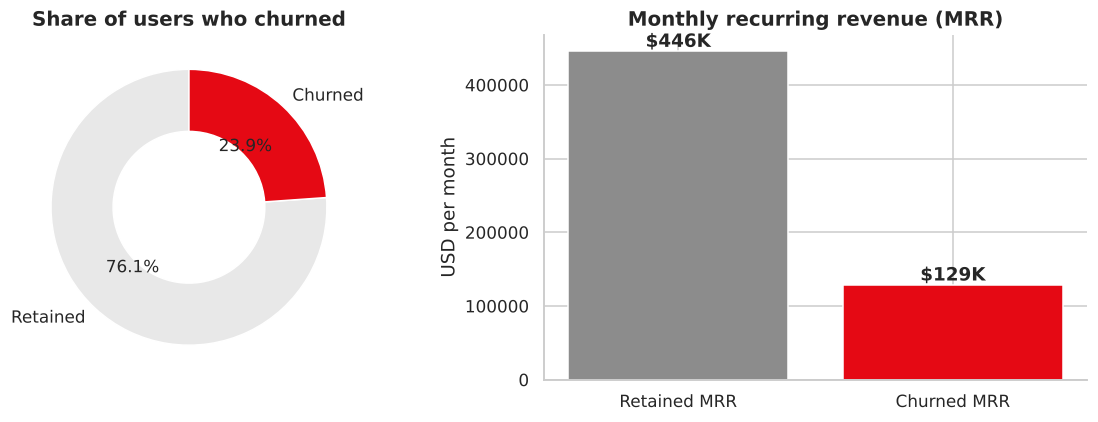

In [ ]:
n_users = len(df)
churn_rate = df["churned"].mean()
n_churned = int(df["churned"].sum())

# Monthly recurring revenue (MRR): what active users pay vs what churned users used to pay
mrr_total = df["monthly_fee"].sum()
mrr_lost = df.loc[df["churned"] == 1, "monthly_fee"].sum()

M.update(n_users=n_users, churn_rate=churn_rate, n_churned=n_churned,
         mrr_total=mrr_total, mrr_lost=mrr_lost, mrr_lost_share=mrr_lost / mrr_total)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].pie([n_users - n_churned, n_churned], labels=["Retained", "Churned"],
            colors=[LIGHT, RED], autopct="%1.1f%%", startangle=90,
            wedgeprops={"width": 0.45, "edgecolor": "white"}, textprops={"fontsize": 11})
axes[0].set_title("Share of users who churned")

axes[1].bar(["Retained MRR", "Churned MRR"], [mrr_total - mrr_lost, mrr_lost], color=[GREY, RED])
for i, v in enumerate([mrr_total - mrr_lost, mrr_lost]):
    axes[1].text(i, v, f"${v/1000:,.0f}K", ha="center", va="bottom", fontweight="bold")
axes[1].set_title("Monthly recurring revenue (MRR)")
axes[1].set_ylabel("USD per month")
savefig("01_churn_baseline")

print(f"📌 Insight: {pct(churn_rate)} of users ({n_churned:,} of {n_users:,}) have churned, "
      f"representing ${mrr_lost:,.0f}/month ({pct(mrr_lost / mrr_total)} of total MRR) that no longer pays.")

**Reading the result:** roughly one in four subscribers has already left. Churn is common enough that even small percentage-point improvements are worth real money — we quantify this in Section 8.

### 3.2 Subscription tier & revenue distribution
**Question:** How are users spread across Basic / Standard / Premium, and who generates the revenue?

,users,mrr,avg_fee,user_share,revenue_share
subscription_type,,,,,
Basic,17872,130575.98,7.31,35.7%,22.7%
Standard,21020,259084.50,12.33,42.0%,45.1%
Premium,11108,184589.26,16.62,22.2%,32.1%


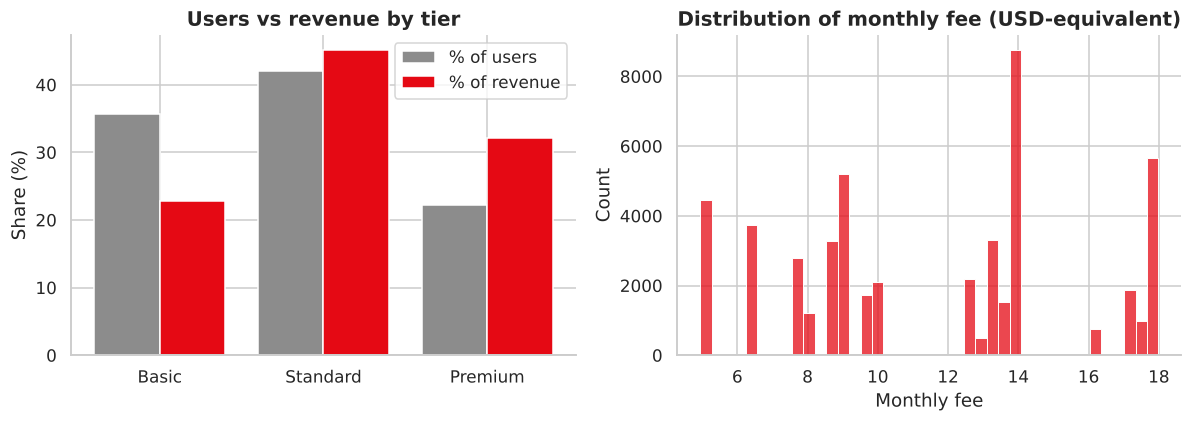

In [ ]:
tier = (df.groupby("subscription_type")
          .agg(users=("user_id", "count"), mrr=("monthly_fee", "sum"), avg_fee=("monthly_fee", "mean"))
          .loc[TIER_ORDER])
tier["user_share"] = tier["users"] / tier["users"].sum()
tier["revenue_share"] = tier["mrr"] / tier["mrr"].sum()
M["tier_table"] = tier.round(6).reset_index().to_dict("records")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3)
axes[0].bar(x - 0.2, tier["user_share"] * 100, 0.4, label="% of users", color=GREY)
axes[0].bar(x + 0.2, tier["revenue_share"] * 100, 0.4, label="% of revenue", color=RED)
axes[0].set_xticks(x, TIER_ORDER)
axes[0].set_ylabel("Share (%)")
axes[0].set_title("Users vs revenue by tier")
axes[0].legend()

sns.histplot(df["monthly_fee"], bins=40, color=RED, ax=axes[1])
axes[1].set_title("Distribution of monthly fee (USD-equivalent)")
axes[1].set_xlabel("Monthly fee")
savefig("02_tier_distribution")

tier_out = tier.copy()
tier_out["user_share"] = (tier_out["user_share"] * 100).round(1).astype(str) + "%"
tier_out["revenue_share"] = (tier_out["revenue_share"] * 100).round(1).astype(str) + "%"
tier_out.round(2)

In [ ]:
big = tier["revenue_share"].idxmax()
print(f"📌 Insight: Standard is the largest tier by users ({pct(tier.loc['Standard','user_share'])}). "
      f"Premium is only {pct(tier.loc['Premium','user_share'])} of users but earns {pct(tier.loc['Premium','revenue_share'])} of revenue; "
      f"Basic is {pct(tier.loc['Basic','user_share'])} of users and {pct(tier.loc['Basic','revenue_share'])} of revenue. "
      f"Fees vary by country (regional pricing), which is why the fee histogram is multi-modal.")

📌 Insight: Standard is the largest tier by users (42.0%). Premium is only 22.2% of users but earns 32.1% of revenue; Basic is 35.7% of users and 22.7% of revenue. Fees vary by country (regional pricing), which is why the fee histogram is multi-modal.


### 3.3 Engagement spread
**Question:** What do `avg_watch_time_minutes` and `binge_watch_sessions` look like? Is the base dominated by casual viewers or heavy binge-watchers?

Skewness of daily watch time: 1.85 | binge sessions: 1.10
📌 Insight: median daily watch time is 69 min (mean 80); distribution is right-skewed. 40.2% are casual (<60 min), 43.9% regular and 15.8% heavy (>120 min). Only 11.6% binge 6+ times a month — the base is dominated by casual-to-regular viewers, not heavy bingers.


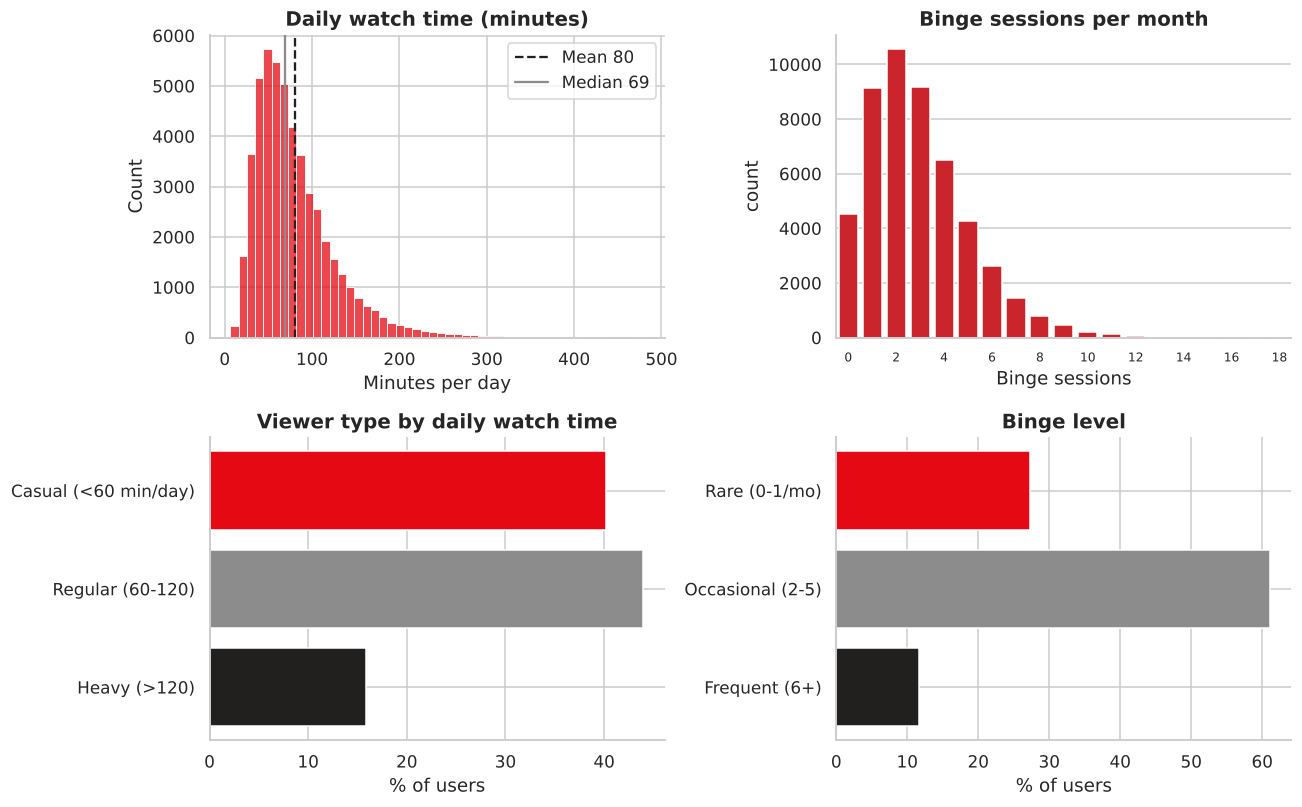

In [ ]:
# Viewer segments (fixed, interpretable thresholds)
df["viewer_type"] = pd.cut(df["avg_watch_time_minutes"], [0, 60, 120, np.inf],
                           labels=["Casual (<60 min/day)", "Regular (60-120)", "Heavy (>120)"])
df["binge_level"] = pd.cut(df["binge_watch_sessions"], [-1, 1, 5, np.inf],
                           labels=["Rare (0-1/mo)", "Occasional (2-5)", "Frequent (6+)"])
VIEWER_ORDER, BINGE_ORDER = list(df["viewer_type"].cat.categories), list(df["binge_level"].cat.categories)

viewer_share = df["viewer_type"].value_counts(normalize=True).loc[VIEWER_ORDER]
binge_share = df["binge_level"].value_counts(normalize=True).loc[BINGE_ORDER]
wt_mean, wt_med = df["avg_watch_time_minutes"].mean(), df["avg_watch_time_minutes"].median()
M.update(watch_mean=wt_mean, watch_median=wt_med,
         casual_share=viewer_share.iloc[0], heavy_share=viewer_share.iloc[2],
         binge_frequent_share=binge_share.iloc[2], binge_rare_share=binge_share.iloc[0])

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
sns.histplot(df["avg_watch_time_minutes"], bins=50, color=RED, ax=axes[0, 0])
axes[0, 0].axvline(wt_mean, color=DARK, ls="--", label=f"Mean {wt_mean:.0f}")
axes[0, 0].axvline(wt_med, color=GREY, ls="-", label=f"Median {wt_med:.0f}")
axes[0, 0].set(title="Daily watch time (minutes)", xlabel="Minutes per day")
axes[0, 0].legend()

sns.countplot(x=df["binge_watch_sessions"], color=RED, ax=axes[0, 1])
axes[0, 1].set(title="Binge sessions per month", xlabel="Binge sessions")
axes[0, 1].set_xticks(range(0, int(df["binge_watch_sessions"].max()) + 1, 2))
axes[0, 1].tick_params(axis="x", labelsize=8)
axes[0, 1].set_xticklabels(range(0, int(df["binge_watch_sessions"].max()) + 1, 2))

axes[1, 0].barh(VIEWER_ORDER[::-1], viewer_share.values[::-1] * 100, color=[RED, GREY, DARK][::-1])
axes[1, 0].set(title="Viewer type by daily watch time", xlabel="% of users")
axes[1, 1].barh(BINGE_ORDER[::-1], binge_share.values[::-1] * 100, color=[RED, GREY, DARK][::-1])
axes[1, 1].set(title="Binge level", xlabel="% of users")
savefig("03_engagement_spread")

print(f"Skewness of daily watch time: {df['avg_watch_time_minutes'].skew():.2f} | binge sessions: {df['binge_watch_sessions'].skew():.2f}")
print(f"📌 Insight: median daily watch time is {wt_med:.0f} min (mean {wt_mean:.0f}); distribution is right-skewed. "
      f"{pct(viewer_share.iloc[0])} are casual (<60 min), {pct(viewer_share.iloc[1])} regular and {pct(viewer_share.iloc[2])} heavy (>120 min). "
      f"Only {pct(binge_share.iloc[2])} binge 6+ times a month — the base is dominated by casual-to-regular viewers, not heavy bingers.")

### 3.4 Dormancy levels
**Question:** How recently have users logged in? What share is dormant or drifting?

📌 Insight: median user last logged in 6 days ago, but 23.5% of all users are At risk or Dormant (14+ days). Crucially, 4,362 subscribers who have NOT churned yet (11.5% of retained users) are already 14+ days inactive — $51,347/month of revenue that can still be saved.


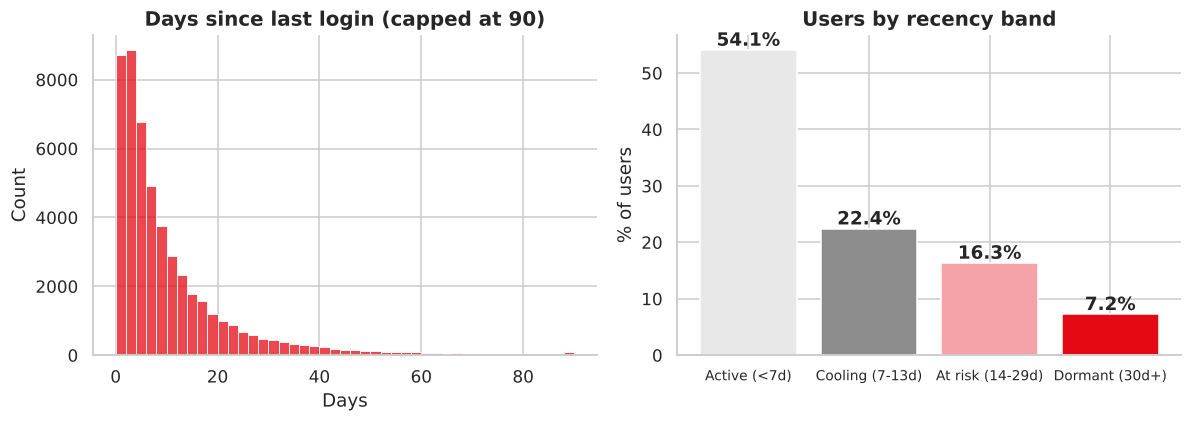

In [ ]:
dorm = df["dormancy_segment"].value_counts(normalize=True).loc[DORM_ORDER]
dsl_med = df["days_since_last_login"].median()

# Among users who have NOT yet churned, how many are already drifting? (still paying -> winnable)
active_df = df[df["churned"] == 0]
drift_mask = active_df["days_since_last_login"] >= 14
n_drift, mrr_drift = int(drift_mask.sum()), active_df.loc[drift_mask, "monthly_fee"].sum()
M.update(dsl_median=dsl_med, dorm_shares=dorm.round(6).to_dict(),
         at_risk_or_dormant_share=dorm.iloc[2:].sum(),
         drifting_subscribers=n_drift, drifting_mrr=mrr_drift,
         drifting_share_of_retained=drift_mask.mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["days_since_last_login"].clip(upper=90), bins=45, color=RED, ax=axes[0])
axes[0].set(title="Days since last login (capped at 90)", xlabel="Days")
axes[1].bar(DORM_ORDER, dorm.values * 100, color=[LIGHT, GREY, "#F5A3A8", RED])
for i, v in enumerate(dorm.values):
    axes[1].text(i, v * 100, f"{v*100:.1f}%", ha="center", va="bottom", fontweight="bold")
axes[1].set(title="Users by recency band", ylabel="% of users")
axes[1].tick_params(axis="x", labelsize=9)
savefig("04_dormancy")

print(f"📌 Insight: median user last logged in {dsl_med:.0f} days ago, but {pct(dorm.iloc[2:].sum())} of all users are At risk or Dormant (14+ days). "
      f"Crucially, {n_drift:,} subscribers who have NOT churned yet ({pct(drift_mask.mean())} of retained users) "
      f"are already 14+ days inactive — ${mrr_drift:,.0f}/month of revenue that can still be saved.")

### 3.5 Demographic reach
**Question:** Where are users located, how old are they and which devices do they prefer?

📌 Insight: USA is the biggest market (24.1%); the top 3 countries hold 50.3% of users. Median age is 35. Smart TV is the most common main device (38.2%), followed by Mobile (26.3%).


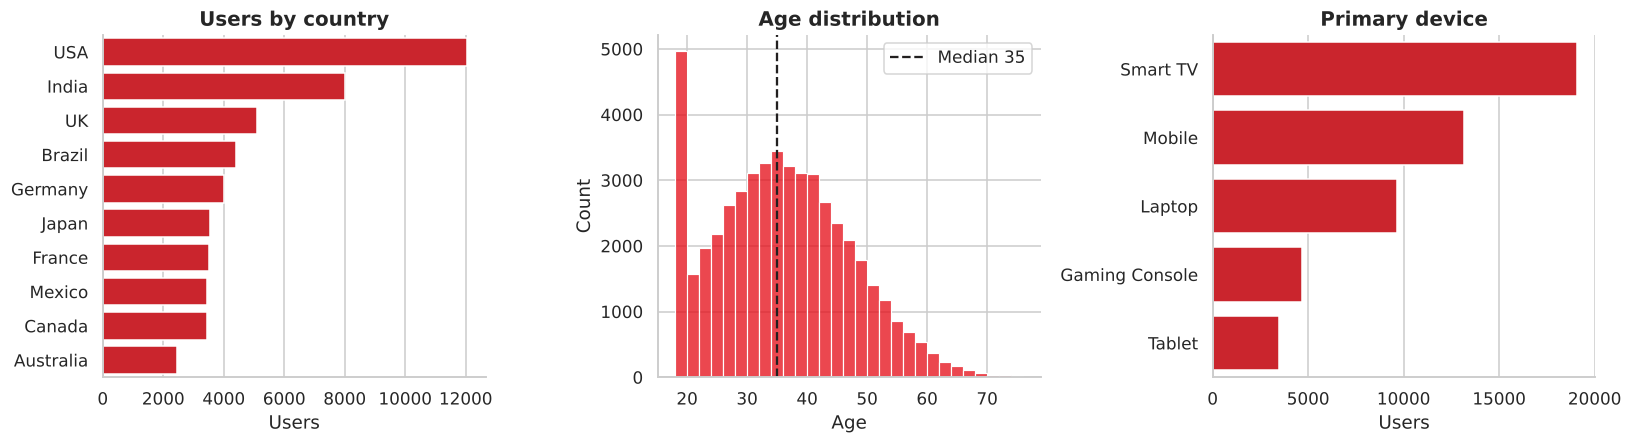

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
order = df["country"].value_counts().index
sns.countplot(y=df["country"], order=order, color=RED, ax=axes[0])
axes[0].set(title="Users by country", xlabel="Users", ylabel="")

sns.histplot(df["age"], bins=range(18, 78, 2), color=RED, ax=axes[1])
axes[1].axvline(df["age"].median(), color=DARK, ls="--", label=f"Median {df['age'].median():.0f}")
axes[1].set(title="Age distribution", xlabel="Age"); axes[1].legend()

dev_order = df["primary_device"].value_counts().index
sns.countplot(y=df["primary_device"], order=dev_order, color=RED, ax=axes[2])
axes[2].set(title="Primary device", xlabel="Users", ylabel="")
savefig("05_demographics")

top_c = df["country"].value_counts(normalize=True)
dev_s = df["primary_device"].value_counts(normalize=True)
M.update(top_country=top_c.index[0], top_country_share=top_c.iloc[0],
         top3_country_share=top_c.iloc[:3].sum(), age_median=df["age"].median(),
         top_device=dev_s.index[0], top_device_share=dev_s.iloc[0],
         mobile_share=dev_s["Mobile"], gender_split=df["gender"].value_counts(normalize=True).round(3).to_dict())

print(f"📌 Insight: {top_c.index[0]} is the biggest market ({pct(top_c.iloc[0])}); the top 3 countries hold {pct(top_c.iloc[:3].sum())} of users. "
      f"Median age is {df['age'].median():.0f}. {dev_s.index[0]} is the most common main device ({pct(dev_s.iloc[0])}), "
      f"followed by Mobile ({pct(dev_s['Mobile'])}).")

## 4. Bivariate Analysis

Pairwise relationships that reveal the *immediate* drivers of churn and engagement. Churn rates are shown with 95% Wilson confidence intervals so that small differences are not over-interpreted.

### 4.1 Subscription tier vs churn
**Question:** Do Basic users churn more than Premium users, or is it really about price?

📌 Insight: Basic churns at 29.8% vs 16.7% for Premium — 1.8x higher. Within Basic, the highest-priced third churns at 31.3% vs 28.3% for the lowest-priced third (+3.0 pts): the tier itself matters far more than the exact local price level.


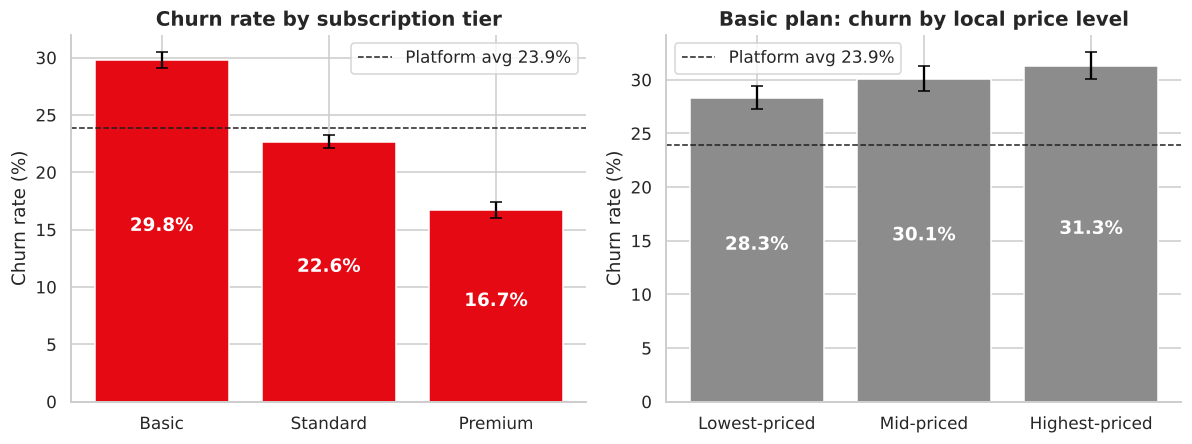

In [ ]:
def churn_table(data, by):
    """Churn rate, group size and 95% CI for each level of `by`."""
    g = data.groupby(by, observed=True)["churned"].agg(["sum", "count"])
    g["rate"] = g["sum"] / g["count"]
    ci = [wilson_ci(s, n) for s, n in zip(g["sum"], g["count"])]
    g["lo"], g["hi"] = [c[0] for c in ci], [c[1] for c in ci]
    return g


def plot_churn_bars(g, ax, title, color=RED, rotate=0):
    """Bar chart of churn rate with CI error bars and the platform baseline."""
    ax.bar(g.index.astype(str), g["rate"] * 100, color=color,
           yerr=[(g["rate"] - g["lo"]) * 100, (g["hi"] - g["rate"]) * 100], capsize=4)
    ax.axhline(churn_rate * 100, color=DARK, ls="--", lw=1, label=f"Platform avg {churn_rate*100:.1f}%")
    for i, v in enumerate(g["rate"]):
        ax.text(i, v * 100 / 2, f"{v*100:.1f}%", ha="center", color="white", fontweight="bold")
    ax.set(title=title, ylabel="Churn rate (%)")
    ax.tick_params(axis="x", rotation=rotate)
    ax.legend()


tier_churn = churn_table(df, "subscription_type").loc[TIER_ORDER]
M["tier_churn"] = tier_churn["rate"].round(6).to_dict()

# Price sensitivity inside the Basic plan: does a higher local price push churn up?
basic = df[df["subscription_type"] == "Basic"].copy()
basic["fee_band"] = pd.qcut(basic["monthly_fee"], 3, labels=["Lowest-priced", "Mid-priced", "Highest-priced"])
basic_fee_churn = churn_table(basic, "fee_band")
M["basic_fee_churn"] = basic_fee_churn["rate"].round(6).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
plot_churn_bars(tier_churn, axes[0], "Churn rate by subscription tier")
plot_churn_bars(basic_fee_churn, axes[1], "Basic plan: churn by local price level", color=GREY)
savefig("06_tier_vs_churn")

ratio = tier_churn.loc["Basic", "rate"] / tier_churn.loc["Premium", "rate"]
M["basic_vs_premium_ratio"] = ratio
print(f"📌 Insight: Basic churns at {pct(tier_churn.loc['Basic','rate'])} vs {pct(tier_churn.loc['Premium','rate'])} for Premium — {ratio:.1f}x higher. "
      f"Within Basic, the highest-priced third churns at {pct(basic_fee_churn.loc['Highest-priced','rate'])} vs {pct(basic_fee_churn.loc['Lowest-priced','rate'])} "
      f"for the lowest-priced third ({100*(basic_fee_churn.loc['Highest-priced','rate']-basic_fee_churn.loc['Lowest-priced','rate']):+.1f} pts): "
      f"the tier itself matters far more than the exact local price level.")

### 4.2 Watch time vs churn
**Question:** How strongly do watch time and binge sessions track retention, and where does churn fall off a cliff?

,feature,pearson_r,spearman_rho
0,avg_watch_time_minutes,-0.227,-0.259
1,binge_watch_sessions,-0.171,-0.173
2,watch_sessions_per_week,-0.113,-0.112


📌 Insight: users watching <30 min/day churn at 50.0%; those watching 150+ min churn at 7.1%. Churn first falls below the platform average in the '60-90' min/day band, and the steepest single drop happens when moving into '30-60' min/day.


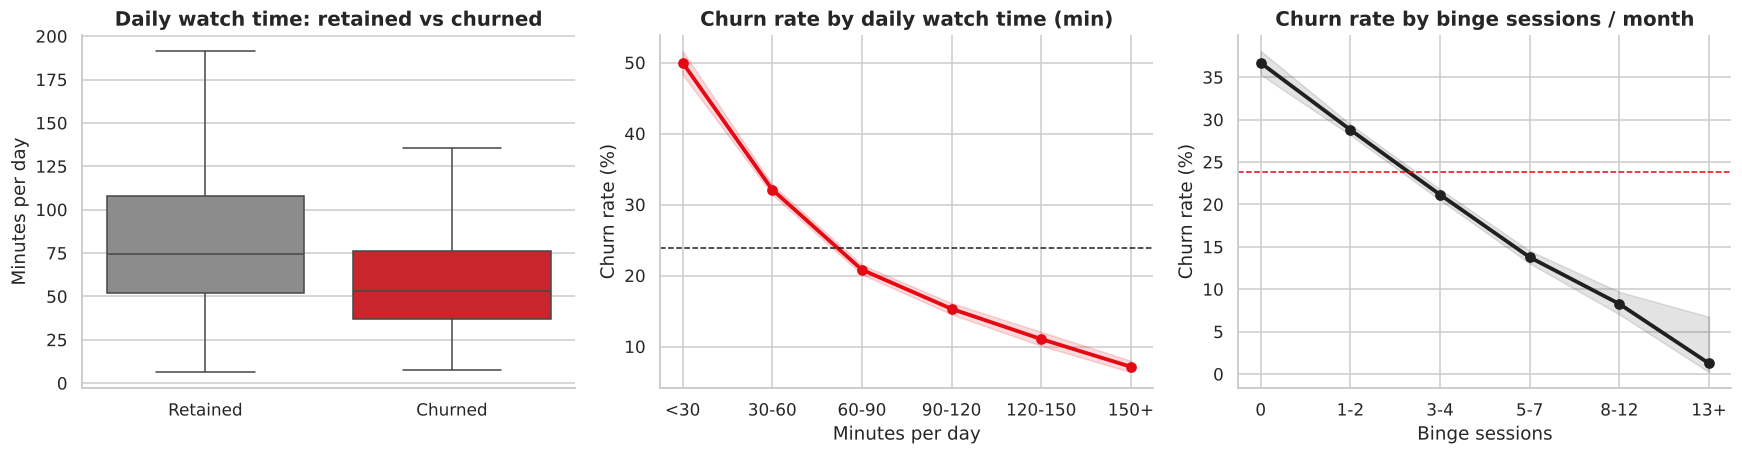

In [ ]:
# Correlation of usage with churn (point-biserial = Pearson on a 0/1 variable; Spearman is robust to skew)
rows = []
for col in ["avg_watch_time_minutes", "binge_watch_sessions", "watch_sessions_per_week"]:
    rows.append({"feature": col,
                 "pearson_r": df[col].corr(df["churned"]),
                 "spearman_rho": df[col].corr(df["churned"], method="spearman")})
corr_churn = pd.DataFrame(rows).round(3)
M["watch_corr"] = corr_churn.set_index("feature")["spearman_rho"].to_dict()

# Churn by watch-time band to locate the threshold
wt_bins = [0, 30, 60, 90, 120, 150, 500]
wt_labels = ["<30", "30-60", "60-90", "90-120", "120-150", "150+"]
df["watch_band"] = pd.cut(df["avg_watch_time_minutes"], wt_bins, labels=wt_labels)
wt_churn = churn_table(df, "watch_band")
bn_bins = [-1, 0, 2, 4, 7, 12, 100]
bn_labels = ["0", "1-2", "3-4", "5-7", "8-12", "13+"]
df["binge_band"] = pd.cut(df["binge_watch_sessions"], bn_bins, labels=bn_labels)
bn_churn = churn_table(df, "binge_band")

# Threshold = first band where churn is below the platform average; biggest single-step drop
below = wt_churn.index[wt_churn["rate"] < churn_rate]
drop_step = wt_churn["rate"].diff().idxmin()
M.update(binge_churn_zero=bn_churn["rate"].iloc[0], binge_churn_13plus=bn_churn["rate"].iloc[-1])
M.update(watch_threshold_band=str(below[0]), watch_biggest_drop_into=str(drop_step),
         churn_lowest_watch=wt_churn["rate"].iloc[0], churn_highest_watch=wt_churn["rate"].iloc[-1],
         watch_churn_by_band=wt_churn["rate"].round(6).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.boxplot(data=df, x="churned", y="avg_watch_time_minutes", palette=[GREY, RED], showfliers=False, ax=axes[0])
axes[0].set(title="Daily watch time: retained vs churned", xlabel="", ylabel="Minutes per day")
axes[0].set_xticklabels(["Retained", "Churned"])

axes[1].plot(wt_churn.index.astype(str), wt_churn["rate"] * 100, marker="o", color=RED, lw=2.5)
axes[1].fill_between(range(len(wt_churn)), wt_churn["lo"] * 100, wt_churn["hi"] * 100, color=RED, alpha=0.15)
axes[1].axhline(churn_rate * 100, color=DARK, ls="--", lw=1)
axes[1].set(title="Churn rate by daily watch time (min)", xlabel="Minutes per day", ylabel="Churn rate (%)")

axes[2].plot(bn_churn.index.astype(str), bn_churn["rate"] * 100, marker="o", color=DARK, lw=2.5)
axes[2].fill_between(range(len(bn_churn)), bn_churn["lo"] * 100, bn_churn["hi"] * 100, color=DARK, alpha=0.12)
axes[2].axhline(churn_rate * 100, color=RED, ls="--", lw=1)
axes[2].set(title="Churn rate by binge sessions / month", xlabel="Binge sessions", ylabel="Churn rate (%)")
savefig("07_watch_time_vs_churn")

display(corr_churn)
print(f"📌 Insight: users watching <30 min/day churn at {pct(wt_churn['rate'].iloc[0])}; those watching 150+ min churn at {pct(wt_churn['rate'].iloc[-1])}. "
      f"Churn first falls below the platform average in the '{below[0]}' min/day band, and the steepest single drop happens when moving into '{drop_step}' min/day.")

**Interpretation:** retention rises steadily with viewing. Rather than a single magic number, the data suggests a **"60-minutes-a-day habit line"**: below it, users churn at well above the platform average; above it, below average. Users who watch under ~30 minutes a day are the most fragile and the best target for engagement nudges.

### 4.3 Device preference vs engagement
**Question:** Do mobile users engage differently from Smart-TV users? Does using more devices help?

,users,watch_min,completion,binge,churn
primary_device,,,,,
Smart TV,19090,97.81,64.32,3.19,0.21
Gaming Console,4656,86.17,62.64,2.81,0.23
Laptop,9629,78.45,59.48,2.78,0.24
Tablet,3474,70.07,57.45,2.74,0.24
Mobile,13151,56.27,52.52,2.80,0.29


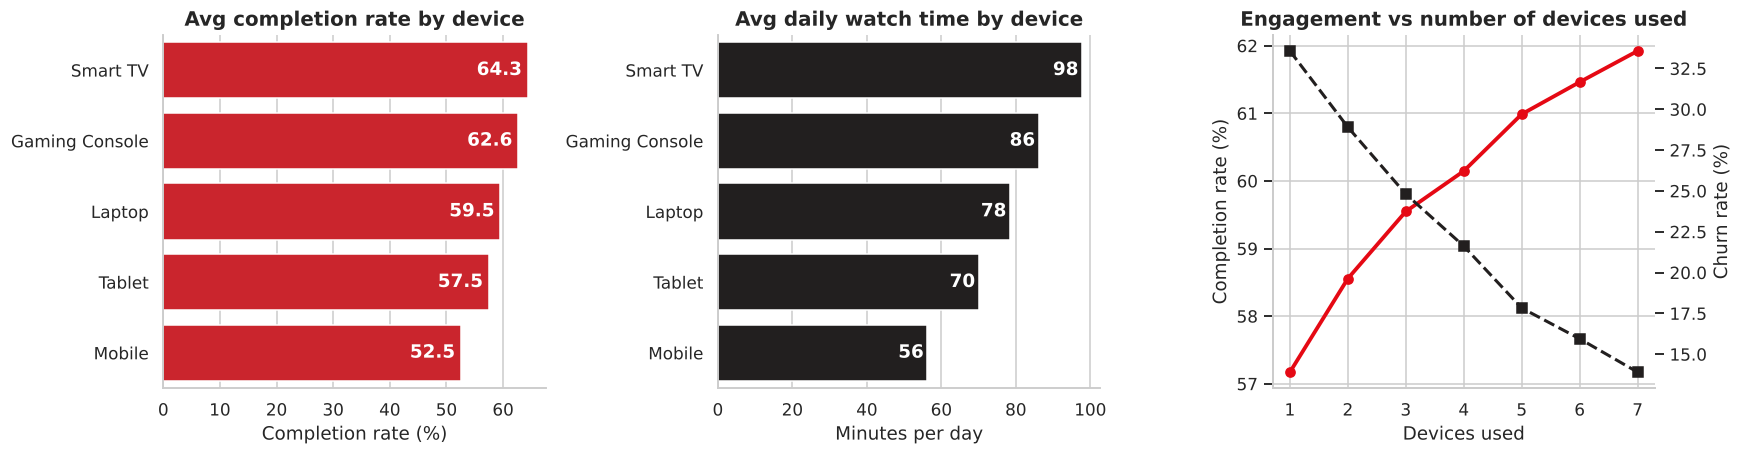

In [ ]:
dev = (df.groupby("primary_device")
         .agg(users=("user_id", "count"),
              watch_min=("avg_watch_time_minutes", "mean"),
              completion=("completion_rate", "mean"),
              binge=("binge_watch_sessions", "mean"),
              churn=("churned", "mean"))
         .sort_values("completion", ascending=False))
M["device_table"] = dev.round(6).reset_index().to_dict("records")
dev_order_c = list(dev.index)

devs_used = df.groupby("devices_used").agg(completion=("completion_rate", "mean"),
                                           watch=("avg_watch_time_minutes", "mean"),
                                           churn=("churned", "mean"), n=("user_id", "count"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.barplot(data=df, y="primary_device", x="completion_rate", order=dev_order_c, color=RED, errorbar=None, ax=axes[0])
axes[0].set(title="Avg completion rate by device", xlabel="Completion rate (%)", ylabel="")
for i, v in enumerate(dev["completion"]):
    axes[0].text(v - 1, i, f"{v:.1f}", ha="right", va="center", color="white", fontweight="bold")

sns.barplot(data=df, y="primary_device", x="avg_watch_time_minutes", order=dev_order_c, color=DARK, errorbar=None, ax=axes[1])
axes[1].set(title="Avg daily watch time by device", xlabel="Minutes per day", ylabel="")
for i, v in enumerate(dev.loc[dev_order_c, "watch_min"]):
    axes[1].text(v - 1, i, f"{v:.0f}", ha="right", va="center", color="white", fontweight="bold")

ax2 = axes[2]
ax2.plot(devs_used.index, devs_used["completion"], marker="o", color=RED, lw=2.5, label="Completion rate")
ax2.set(title="Engagement vs number of devices used", xlabel="Devices used", ylabel="Completion rate (%)")
ax3 = ax2.twinx()
ax3.plot(devs_used.index, devs_used["churn"] * 100, marker="s", color=DARK, lw=2, ls="--", label="Churn rate")
ax3.set_ylabel("Churn rate (%)"); ax3.grid(False)
savefig("08_device_vs_engagement")

M["multi_device_churn"] = {"three_plus": df.loc[df["devices_used"] >= 3, "churned"].mean(),
                           "under_three": df.loc[df["devices_used"] < 3, "churned"].mean()}
M["devices_used_corr_completion"] = df["devices_used"].corr(df["completion_rate"], method="spearman")
dev.round(2)

In [ ]:
tv, mob = dev.loc["Smart TV"], dev.loc["Mobile"]
print(f"📌 Insight: Smart-TV users complete {tv['completion']:.1f}% of content and watch {tv['watch_min']:.0f} min/day; "
      f"Mobile users complete {mob['completion']:.1f}% and watch {mob['watch_min']:.0f} min/day "
      f"(gap: {tv['completion']-mob['completion']:.1f} pts completion, {tv['watch_min']-mob['watch_min']:.0f} min/day). "
      f"Mobile churn is {pct(mob['churn'])} vs {pct(tv['churn'])} on Smart TV. "
      f"Spearman rho between devices_used and completion = {M['devices_used_corr_completion']:.2f}; "
      f"the multi-device (3+) group churns less ({pct(df.loc[df['devices_used']>=3,'churned'].mean())} vs {pct(df.loc[df['devices_used']<3,'churned'].mean())}).")

📌 Insight: Smart-TV users complete 64.3% of content and watch 98 min/day; Mobile users complete 52.5% and watch 56 min/day (gap: 11.8 pts completion, 42 min/day). Mobile churn is 28.6% vs 20.9% on Smart TV. Spearman rho between devices_used and completion = 0.09; the multi-device (3+) group churns less (20.9% vs 30.4%).


### 4.4 Recommendation effectiveness
**Question:** Do users who click recommendations rate more content, interact more and engage more?

📌 Insight: recommendation click rate has Spearman rho = 0.41 with rating, 0.48 with interactions and 0.44 with completion. Users in the top click-rate quintile churn at 12.7% vs 36.8% in the bottom quintile.


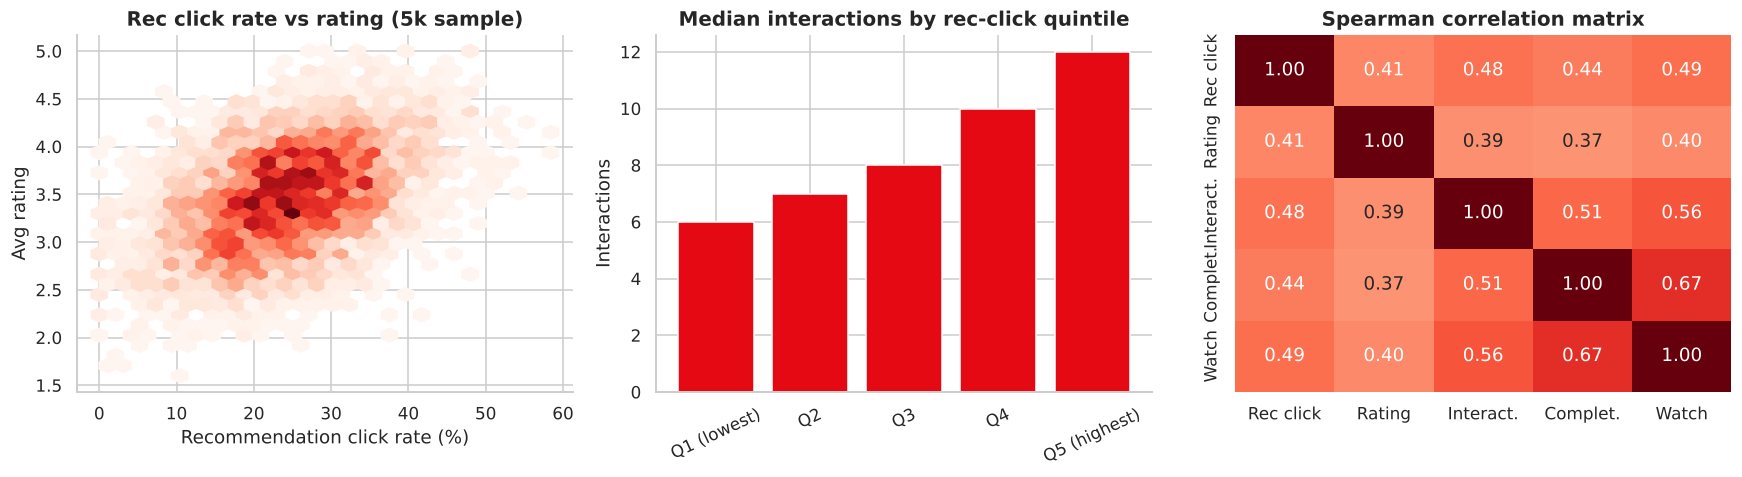

In [ ]:
rec_cols = ["recommendation_click_rate", "rating_given", "content_interactions", "completion_rate", "avg_watch_time_minutes"]
rec_corr = df[rec_cols].corr(method="spearman")
M["rec_corr"] = {"rating": rec_corr.loc["recommendation_click_rate", "rating_given"],
                 "interactions": rec_corr.loc["recommendation_click_rate", "content_interactions"],
                 "completion": rec_corr.loc["recommendation_click_rate", "completion_rate"]}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sample = df.sample(5000, random_state=1)
axes[0].hexbin(sample["recommendation_click_rate"], sample["rating_given"], gridsize=28, cmap="Reds", mincnt=1)
axes[0].set(title="Rec click rate vs rating (5k sample)", xlabel="Recommendation click rate (%)", ylabel="Avg rating")

df["rec_band"] = pd.qcut(df["recommendation_click_rate"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
rb = df.groupby("rec_band", observed=True).agg(interactions=("content_interactions", "median"),
                                                  rating=("rating_given", "mean"), churn=("churned", "mean"))
axes[1].bar(rb.index.astype(str), rb["interactions"], color=RED)
axes[1].set(title="Median interactions by rec-click quintile", ylabel="Interactions")
axes[1].tick_params(axis="x", rotation=25)

sns.heatmap(rec_corr, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, cbar=False, ax=axes[2],
            xticklabels=["Rec click", "Rating", "Interact.", "Complet.", "Watch"],
            yticklabels=["Rec click", "Rating", "Interact.", "Complet.", "Watch"])
axes[2].set_title("Spearman correlation matrix")
savefig("09_recommendation_effectiveness")

M["rec_churn_q1"], M["rec_churn_q5"] = rb["churn"].iloc[0], rb["churn"].iloc[-1]
print(f"📌 Insight: recommendation click rate has Spearman rho = {M['rec_corr']['rating']:.2f} with rating, "
      f"{M['rec_corr']['interactions']:.2f} with interactions and {M['rec_corr']['completion']:.2f} with completion. "
      f"Users in the top click-rate quintile churn at {pct(rb['churn'].iloc[-1])} vs {pct(rb['churn'].iloc[0])} in the bottom quintile.")

**Interpretation:** the recommendation engine works as a **satisfaction signal**: people who click recommendations also rate higher, interact more and churn less. The correlation with rating is moderate rather than strong, so ratings are driven by more than recommendation quality alone. (This is association — satisfied users may simply click more.)

### 4.5 Age & gender vs content preference
**Question:** How do favourite genres cluster across age brackets and gender?

📌 Insight: top genre per age group -> {'18-24': 'Comedy', '25-34': 'Action', '35-44': 'Drama', '45-54': 'Drama', '55+': 'Drama'}
Strongest age x genre affinities (lift vs average): {'55+ | Documentary': 2.19, '18-24 | Animation': 1.89, '45-54 | Documentary': 1.61, '55+ | Drama': 1.48}
Gender: Romance share Female 14% vs Male 4%; Action share Male 20% vs Female 10%


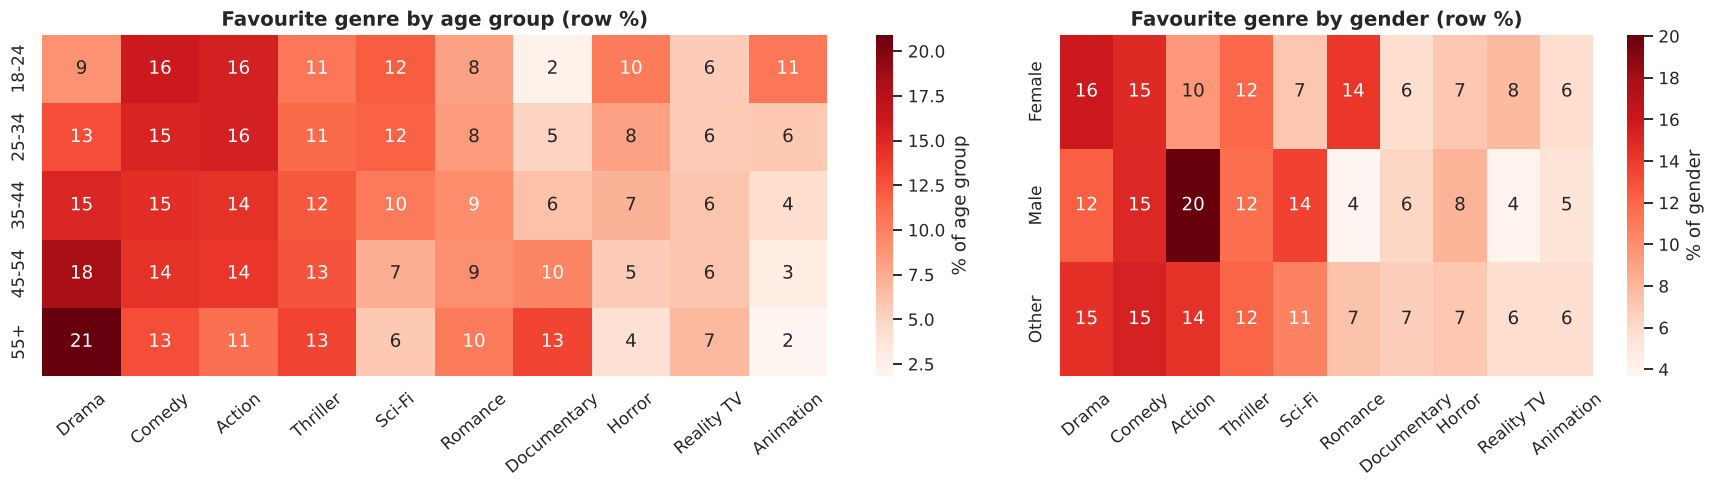

In [ ]:
df["age_group"] = pd.cut(df["age"], [17, 24, 34, 44, 54, 100], labels=["18-24", "25-34", "35-44", "45-54", "55+"])
AGE_ORDER = list(df["age_group"].cat.categories)

genre_age = pd.crosstab(df["age_group"], df["favorite_genre"], normalize="index") * 100
genre_gender = pd.crosstab(df["gender"], df["favorite_genre"], normalize="index") * 100
col_order = genre_age.mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [5, 3.4]})
sns.heatmap(genre_age[col_order], annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of age group"}, ax=axes[0])
axes[0].set(title="Favourite genre by age group (row %)", xlabel="", ylabel="")
sns.heatmap(genre_gender.loc[["Female", "Male", "Other"], col_order], annot=True, fmt=".0f", cmap="Reds",
            cbar_kws={"label": "% of gender"}, ax=axes[1])
axes[1].set(title="Favourite genre by gender (row %)", xlabel="", ylabel="")
for a in axes:
    a.tick_params(axis="x", rotation=40)
savefig("10_genre_by_age_gender")

# Lift = a segment's share of a genre relative to the overall share (1.0 = average)
lift = genre_age.div(df["favorite_genre"].value_counts(normalize=True).mul(100), axis=1)
top_lift = lift.stack().sort_values(ascending=False).head(4)
M["genre_top_lifts"] = {f"{a} | {g}": round(v, 2) for (a, g), v in top_lift.items()}
M["genre_top_by_age"] = genre_age.idxmax(axis=1).to_dict()
print("📌 Insight: top genre per age group ->", M["genre_top_by_age"])
print("Strongest age x genre affinities (lift vs average):", M["genre_top_lifts"])
print("Gender: Romance share Female {:.0f}% vs Male {:.0f}%; Action share Male {:.0f}% vs Female {:.0f}%".format(
    genre_gender.loc["Female", "Romance"], genre_gender.loc["Male", "Romance"],
    genre_gender.loc["Male", "Action"], genre_gender.loc["Female", "Action"]))

**Interpretation:** taste is clearly age-structured — the youngest group over-indexes on Animation, while 45+ viewers over-index on Documentary and Drama — and gender shows a clear Romance (female) vs Action (male) split. This supports **age-aware homepage curation and marketing creative**.

## 5. Multivariate Analysis

Churn is rarely caused by a single factor. Here we combine three or more variables to find the *segments* that are disproportionately at risk (or unusually loyal).

### 5.1 Profiling churned users
**Question:** How do tier, fee, watch time and recency combine to define the profile of users who churn?

In [ ]:
# Side-by-side profile of churned vs retained users
profile = (df.groupby("churned")
             .agg(users=("user_id", "count"),
                  avg_fee=("monthly_fee", "mean"),
                  median_watch_min=("avg_watch_time_minutes", "median"),
                  median_days_since_login=("days_since_last_login", "median"),
                  basic_share=("subscription_type", lambda s: (s == "Basic").mean()),
                  premium_share=("subscription_type", lambda s: (s == "Premium").mean()),
                  engagement_index=("engagement_index", "mean"),
                  completion=("completion_rate", "mean"))
             .rename(index={0: "Retained", 1: "Churned"}))
M["profile"] = profile.round(3).reset_index().to_dict("records")
profile.round(2).T

churned,Retained,Churned
users,38061.00,11939.00
avg_fee,11.71,10.77
median_watch_min,74.60,52.90
median_days_since_login,4.00,18.00
basic_share,0.33,0.45
premium_share,0.24,0.16
engagement_index,39.72,33.86
completion,61.47,53.87


📌 Insight: the riskiest combination is Basic + Low watch time (churn 45.2%); the safest is Premium + High watch time (8.0%) — a 5.7x spread. Recency separates users sharply: even Premium users 30+ days inactive churn at 84.2%.


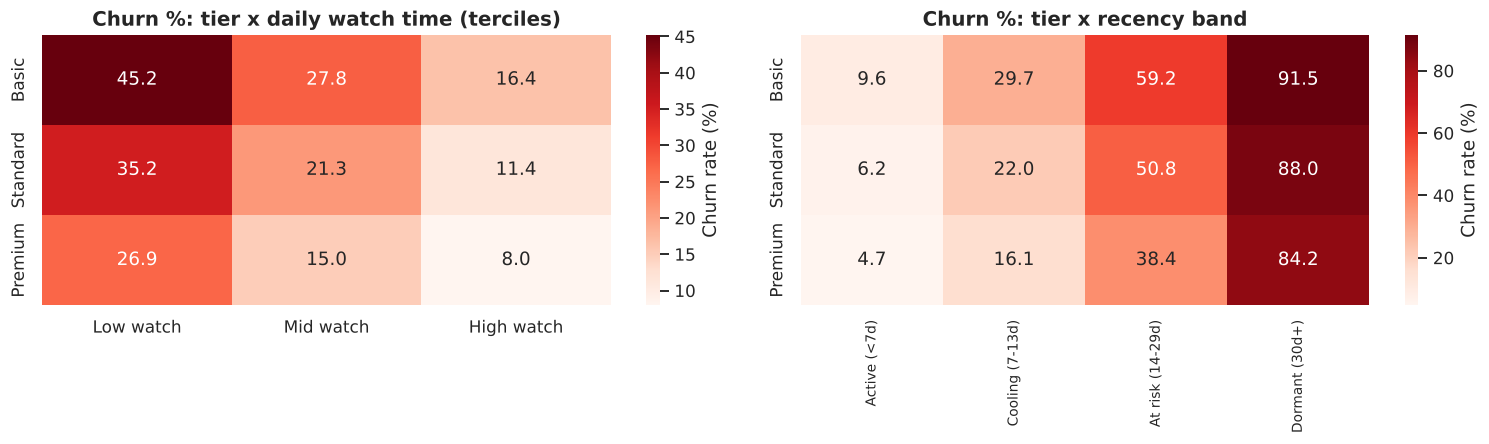

In [ ]:
# Heatmaps: churn rate for tier x watch-time band, and tier x recency band
df["watch_tercile"] = pd.qcut(df["avg_watch_time_minutes"], 3, labels=["Low watch", "Mid watch", "High watch"])
h1 = df.pivot_table(index="subscription_type", columns="watch_tercile", values="churned", aggfunc="mean", observed=True).loc[TIER_ORDER]
h2 = df.pivot_table(index="subscription_type", columns="dormancy_segment", values="churned", aggfunc="mean", observed=True).loc[TIER_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(h1 * 100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=axes[0])
axes[0].set(title="Churn %: tier x daily watch time (terciles)", xlabel="", ylabel="")
sns.heatmap(h2 * 100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=axes[1])
axes[1].set(title="Churn %: tier x recency band", xlabel="", ylabel="")
axes[1].tick_params(axis="x", labelsize=9)
savefig("11_churn_profile_heatmaps")

M["highest_risk_cell"] = {"tier": "Basic", "watch": "Low watch", "churn": h1.loc["Basic", "Low watch"]}
M["lowest_risk_cell"] = {"tier": "Premium", "watch": "High watch", "churn": h1.loc["Premium", "High watch"]}
print(f"📌 Insight: the riskiest combination is Basic + Low watch time (churn {pct(h1.loc['Basic','Low watch'])}); "
      f"the safest is Premium + High watch time ({pct(h1.loc['Premium','High watch'])}) — a {h1.loc['Basic','Low watch']/h1.loc['Premium','High watch']:.1f}x spread. "
      f"Recency separates users sharply: even Premium users 30+ days inactive churn at {pct(h2.loc['Premium','Dormant (30d+)'])}.")

**Behavioural segmentation (K-Means).** Heatmaps need us to pick the cut-points. To let the data propose segments, we cluster users on seven standardised behaviour metrics (excluding `churned` and `days_since_last_login` so segments describe *behaviour*, not outcome), then profile each cluster.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

behaviour_cols = ["avg_watch_time_minutes", "watch_sessions_per_week", "binge_watch_sessions",
                  "completion_rate", "rating_given", "content_interactions", "recommendation_click_rate"]
X = StandardScaler().fit_transform(df[behaviour_cols])

# Pick k with the silhouette score on a sample (full silhouette is O(n^2))
from sklearn.metrics import silhouette_score
idx = np.random.RandomState(0).choice(len(df), 6000, replace=False)
sil = {}
for k in range(2, 7):
    labels_k = KMeans(n_clusters=k, n_init=5, random_state=42).fit_predict(X[idx])
    sil[k] = silhouette_score(X[idx], labels_k)
print("Silhouette by k:", {k: round(v, 3) for k, v in sil.items()})

K = 4   # business-friendly number of segments; silhouette check above shows the structure is a gradient, not sharply separated blobs
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["cluster"] = km.labels_

# Name clusters from their behaviour: lowest / highest daily watch time = Disengaged / Super-fans;
# the two middle clusters watch similar minutes but differ in session pattern (frequent-short vs few-long)
rank = df.groupby("cluster")["avg_watch_time_minutes"].mean().sort_values().index
mid = sorted(rank[1:-1], key=lambda c: df.loc[df["cluster"] == c, "watch_sessions_per_week"].mean(), reverse=True)
name_map = {rank[0]: "Disengaged", mid[0]: "Habitual viewers", mid[1]: "Long-session viewers", rank[-1]: "Super-fans"}
df["segment"] = df["cluster"].map(name_map)
SEG_ORDER = ["Disengaged", "Habitual viewers", "Long-session viewers", "Super-fans"]
MID_SEGS = ["Habitual viewers", "Long-session viewers"]

seg = (df.groupby("segment")
         .agg(users=("user_id", "count"), watch_min=("avg_watch_time_minutes", "mean"),
              sessions=("watch_sessions_per_week", "mean"), binge=("binge_watch_sessions", "mean"),
              completion=("completion_rate", "mean"), rec_click=("recommendation_click_rate", "mean"),
              avg_fee=("monthly_fee", "mean"), churn=("churned", "mean"))
         .loc[SEG_ORDER])
seg["share"] = seg["users"] / seg["users"].sum()
M["segments"] = seg.round(6).reset_index().to_dict("records")
seg.round(2)

Silhouette by k: {2: 0.268, 3: 0.178, 4: 0.158, 5: 0.135, 6: 0.129}


,users,watch_min,sessions,binge,completion,rec_click,avg_fee,churn,share
segment,,,,,,,,,
Disengaged,17038,46.68,3.51,1.69,48.40,16.78,11.47,0.38,0.34
Habitual viewers,9343,81.75,7.37,2.97,62.43,26.55,11.41,0.19,0.19
Long-session viewers,16392,80.86,3.41,3.01,62.78,26.73,11.50,0.19,0.33
Super-fans,7227,155.31,6.05,5.67,75.50,34.46,11.57,0.07,0.14


The two middle segments churn at 19.2% and 19.2%: same minutes watched, different rhythm (many short vs few long sessions).
📌 Insight: 'Disengaged' users (34.1% of base) churn at 37.9%, versus 7.4% for 'Super-fans' (14.5% of base) — a 5.1x gap driven purely by behaviour.


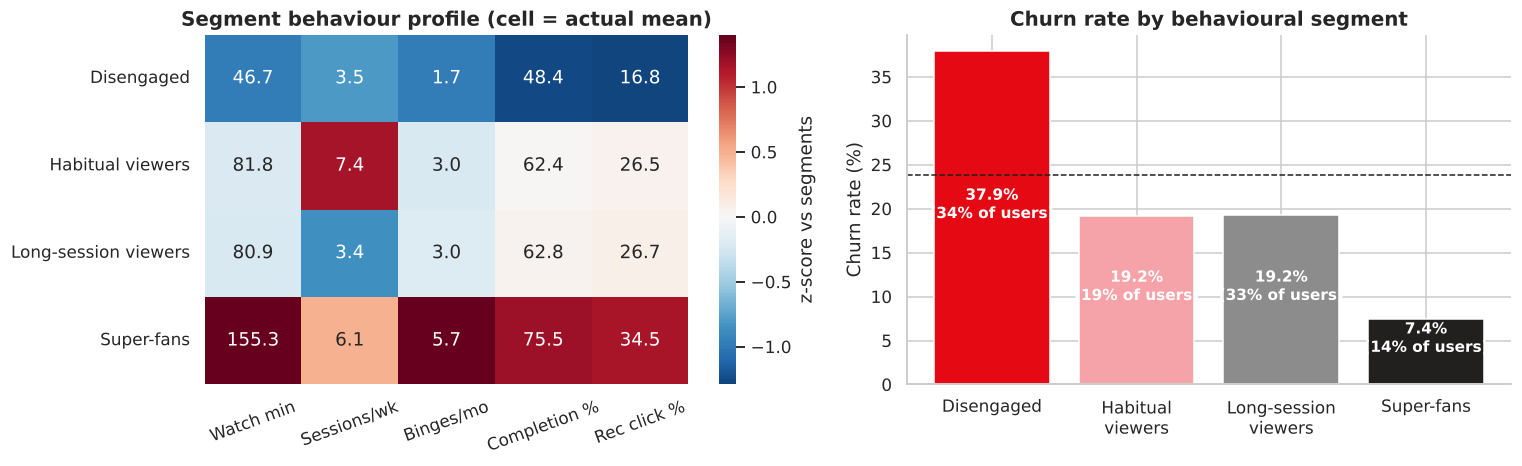

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
prof = seg[["watch_min", "sessions", "binge", "completion", "rec_click"]]
prof_z = (prof - prof.mean()) / prof.std()
sns.heatmap(prof_z, annot=prof.round(1), fmt="", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score vs segments"}, ax=axes[0])
axes[0].set(title="Segment behaviour profile (cell = actual mean)", xlabel="", ylabel="")
axes[0].set_xticklabels(["Watch min", "Sessions/wk", "Binges/mo", "Completion %", "Rec click %"], rotation=20)

bars = axes[1].bar(seg.index, seg["churn"] * 100, color=[RED, "#F5A3A8", GREY, DARK])
axes[1].axhline(churn_rate * 100, color=DARK, ls="--", lw=1)
for b, (n, row) in zip(bars, seg.iterrows()):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() / 2, f"{row['churn']*100:.1f}%\n({row['share']*100:.0f}% of users)",
                 ha="center", color="white", fontweight="bold", fontsize=10)
axes[1].set(title="Churn rate by behavioural segment", ylabel="Churn rate (%)")
axes[1].set_xticklabels([n.replace(" ", "\n") for n in seg.index])      # wrap long names so they do not collide
savefig("12_segments")

hi, lo = seg["churn"].idxmax(), seg["churn"].idxmin()
M.update(seg_highest=hi, seg_lowest=lo)
mid_churn = df.loc[df["segment"].isin(MID_SEGS), "churned"].mean()
print(f"The two middle segments churn at {pct(seg.loc['Habitual viewers','churn'])} and {pct(seg.loc['Long-session viewers','churn'])}: "
      f"same minutes watched, different rhythm (many short vs few long sessions).")
print(f"📌 Insight: '{hi}' users ({pct(seg.loc[hi,'share'])} of base) churn at {pct(seg.loc[hi,'churn'])}, "
      f"versus {pct(seg.loc[lo,'churn'])} for '{lo}' ({pct(seg.loc[lo,'share'])} of base) — "
      f"a {seg.loc[hi,'churn']/seg.loc[lo,'churn']:.1f}x gap driven purely by behaviour.")

**Reading the segments:** Disengaged users (about a third of the base) watch under an hour a day, rarely click recommendations and churn at about 1.6x the platform average. Super-fans are the opposite: 2.5+ hours a day, high completion and the lowest churn. The two middle segments watch about the same number of minutes, but one watches in many short sessions (*Habitual*) and the other in few long ones (*Long-session*); both retain similarly well, so **total engagement, not session style, is what protects against churn**.

### 5.2 Content engagement & platform stickiness
**Question:** Across device types and age groups, how do binge sessions and interactions jointly drive a high completion rate?

📌 Insight: completion ranges from 48.7% (binge '0' / low interact.) to 86.2% (binge '13+' / high interact.): binge volume and interaction depth move together with completion. Device matters on top of that — the gap between the best and worst device is 12.0 pts and is similar across age groups, so it is a device effect, not an age effect.


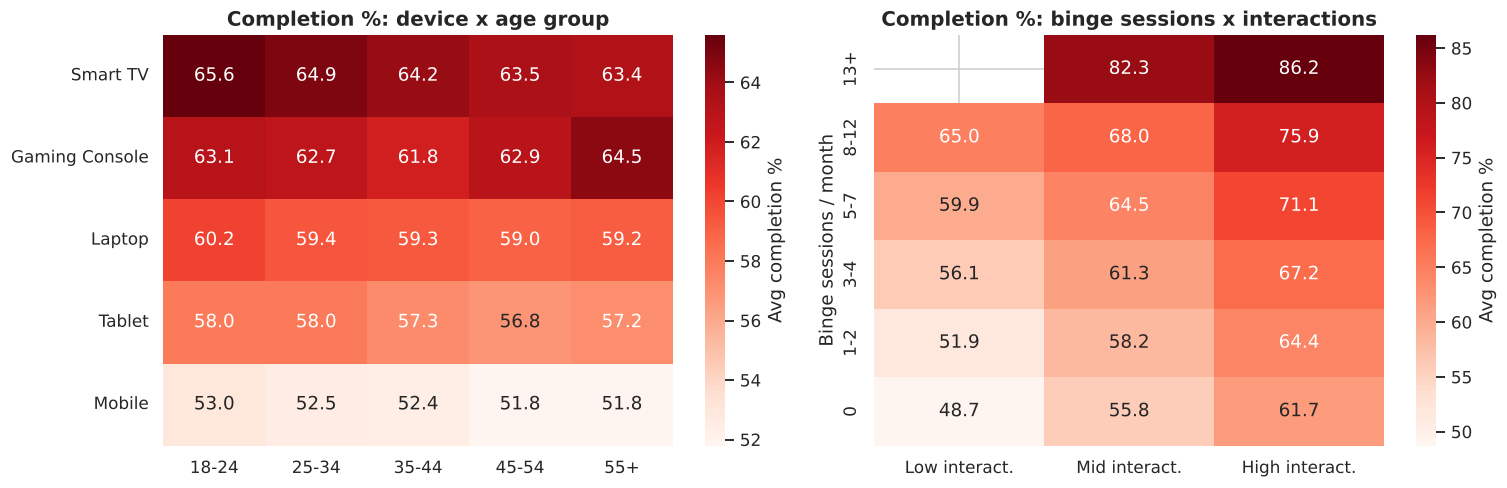

In [ ]:
df["interaction_tercile"] = pd.qcut(df["content_interactions"], 3, labels=["Low interact.", "Mid interact.", "High interact."])
g1 = df.pivot_table(index="primary_device", columns="age_group", values="completion_rate", aggfunc="mean", observed=True)
g2 = df.pivot_table(index="binge_band", columns="interaction_tercile", values="completion_rate", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(g1.loc[dev_order_c], annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Avg completion %"}, ax=axes[0])
axes[0].set(title="Completion %: device x age group", xlabel="", ylabel="")
sns.heatmap(g2.iloc[::-1], annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Avg completion %"}, ax=axes[1])
axes[1].set(title="Completion %: binge sessions x interactions", xlabel="", ylabel="Binge sessions / month")
savefig("13_stickiness_heatmaps")

g2_flat = g2.stack()                                  # drops empty cells (NaN) before ranking
lo_cell, hi_cell = g2_flat.idxmin(), g2_flat.idxmax()
M["completion_max_cell"], M["completion_min_cell"] = float(g2_flat.max()), float(g2_flat.min())
print(f"📌 Insight: completion ranges from {g2_flat.min():.1f}% (binge '{lo_cell[0]}' / {lo_cell[1].lower()}) to {g2_flat.max():.1f}% "
      f"(binge '{hi_cell[0]}' / {hi_cell[1].lower()}): binge volume and interaction depth move together with completion. "
      f"Device matters on top of that — the gap between the best and worst device is {g1.mean(axis=1).max()-g1.mean(axis=1).min():.1f} pts "
      f"and is similar across age groups, so it is a device effect, not an age effect.")

### 5.3 Price sensitivity across regions
**Question:** How do country, monthly fee and tier combine to shape premium vs budget adoption — and does the Basic-tier churn penalty differ by market?

📌 Insight: Premium adoption ranges from 30% in USA to 10% in India. In price-sensitive markets (India, Brazil, Mexico) 51.6% of users are on Basic vs 28.4% elsewhere. The Basic tier churns more than Premium in every market (highest Basic churn: Australia at 36.3%).


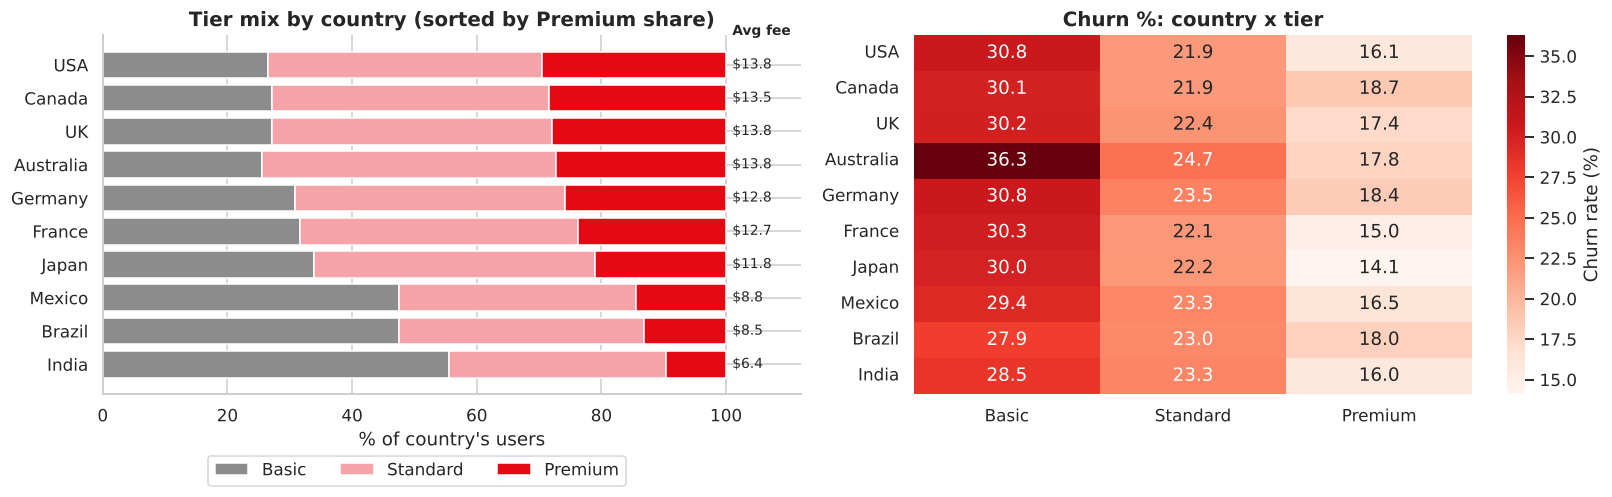

In [ ]:
mix = pd.crosstab(df["country"], df["subscription_type"], normalize="index")[TIER_ORDER] * 100
mix = mix.sort_values("Premium", ascending=False)
fee_c = df.groupby("country")["monthly_fee"].mean().loc[mix.index]
cc = df.pivot_table(index="country", columns="subscription_type", values="churned", aggfunc="mean").loc[mix.index, TIER_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
left = np.zeros(len(mix))
for t, c in zip(TIER_ORDER, [GREY, "#F5A3A8", RED]):
    axes[0].barh(mix.index, mix[t], left=left, color=c, label=t)
    left += mix[t].values
axes[0].invert_yaxis()
for i, (cty, f) in enumerate(fee_c.items()):
    axes[0].text(101, i, f"${f:.1f}", va="center", fontsize=9)
axes[0].text(101, -0.9, "Avg fee", fontsize=9, fontweight="bold")
axes[0].set(title="Tier mix by country (sorted by Premium share)", xlabel="% of country's users", xlim=(0, 112))
axes[0].legend(loc="lower center", ncol=3, bbox_to_anchor=(0.45, -0.28))

sns.heatmap(cc * 100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=axes[1])
axes[1].set(title="Churn %: country x tier", xlabel="", ylabel="")
savefig("14_regional_price_sensitivity")

low_markets = ["India", "Brazil", "Mexico"]
M["premium_share_top"] = {mix.index[0]: mix["Premium"].iloc[0]}
M["premium_share_bottom"] = {mix.index[-1]: mix["Premium"].iloc[-1]}
M["basic_share_low_markets"] = float((df[df.country.isin(low_markets)]["subscription_type"] == "Basic").mean())
M["basic_share_other_markets"] = float((df[~df.country.isin(low_markets)]["subscription_type"] == "Basic").mean())
M["basic_churn_by_country_max"] = {cc["Basic"].idxmax(): float(cc["Basic"].max())}
print(f"📌 Insight: Premium adoption ranges from {mix['Premium'].iloc[0]:.0f}% in {mix.index[0]} to {mix['Premium'].iloc[-1]:.0f}% in {mix.index[-1]}. "
      f"In price-sensitive markets (India, Brazil, Mexico) {pct(M['basic_share_low_markets'])} of users are on Basic vs {pct(M['basic_share_other_markets'])} elsewhere. "
      f"The Basic tier churns more than Premium in every market (highest Basic churn: {cc['Basic'].idxmax()} at {pct(cc['Basic'].max())}).")

### 5.4 Recommendation trust dynamics
**Question:** How do recommendation click rate, completion rate and rating combine to identify the most valuable, most satisfied users?

📌 Insight: 'Satisfied advocates' (33.0% of users) rate 3.74/5, churn at 13.2%; 'Detached' users (32.4%) rate 3.21/5 and churn at 36.3% — 2.7x higher. Trust in recommendations plus finishing content is the clearest stickiness signature.


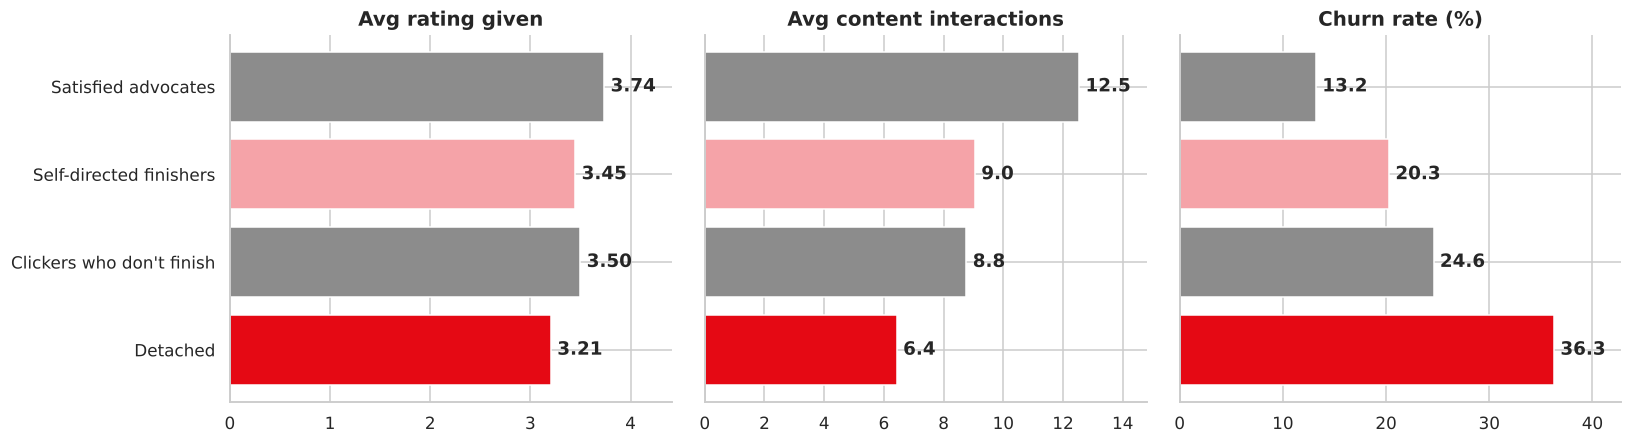

In [ ]:
# 2x2 grid: does the user click recommendations (trust) and finish what they start (satisfaction)?
hi_click = df["recommendation_click_rate"] >= df["recommendation_click_rate"].median()
hi_comp = df["completion_rate"] >= df["completion_rate"].median()
df["trust_segment"] = np.select(
    [hi_click & hi_comp, hi_click & ~hi_comp, ~hi_click & hi_comp],
    ["Satisfied advocates", "Clickers who don't finish", "Self-directed finishers"],
    default="Detached")
TRUST_ORDER = ["Satisfied advocates", "Self-directed finishers", "Clickers who don't finish", "Detached"]

trust = (df.groupby("trust_segment")
           .agg(users=("user_id", "count"), rating=("rating_given", "mean"), interactions=("content_interactions", "mean"),
                watch_min=("avg_watch_time_minutes", "mean"), churn=("churned", "mean"), avg_fee=("monthly_fee", "mean"))
           .loc[TRUST_ORDER])
trust["share"] = trust["users"] / trust["users"].sum()
M["trust"] = trust.round(6).reset_index().to_dict("records")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title, fmt in zip(axes, ["rating", "interactions", "churn"],
                               ["Avg rating given", "Avg content interactions", "Churn rate (%)"], ["{:.2f}", "{:.1f}", "{:.1f}"]):
    vals = trust[col] * (100 if col == "churn" else 1)
    ax.barh(trust.index[::-1], vals.values[::-1], color=[GREY, "#F5A3A8", GREY, RED][::-1] if col != "churn" else [GREY, "#F5A3A8", GREY, RED][::-1])
    for i, v in enumerate(vals.values[::-1]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontweight="bold")
    ax.set_title(title); ax.set_xlim(0, vals.max() * 1.18)
axes[1].set_yticklabels([]); axes[2].set_yticklabels([])
savefig("15_trust_segments")

a, d = trust.loc["Satisfied advocates"], trust.loc["Detached"]
print(f"📌 Insight: 'Satisfied advocates' ({pct(a['share'])} of users) rate {a['rating']:.2f}/5, churn at {pct(a['churn'])}; "
      f"'Detached' users ({pct(d['share'])}) rate {d['rating']:.2f}/5 and churn at {pct(d['churn'])} — "
      f"{d['churn']/a['churn']:.1f}x higher. Trust in recommendations plus finishing content is the clearest stickiness signature.")

## 6. Longitudinal / Cohort Analysis (using tenure)

There are no timestamps, but `account_age_months` (tenure) and `days_since_last_login` (recency) let us reconstruct a *lifecycle view*: how behaviour and risk change as an account ages.

> **Caveat:** this is a cross-sectional snapshot, so a 36-month account is not the same people as the 3-month accounts three years ago. Treat curves as "what the base looks like at each age", not a true survival curve.

### 6.1 Tenure-based churn curves
**Question:** At which account-age milestone is churn most concentrated?

📌 Insight: first-3-month accounts churn at 28.4%. Cohort churn: New (<6m) 26.7%, Established (6-24m) 23.7%, Veteran (>24m) 23.3%. New accounts make up 11.1% of users but 12.4% of churners. Highest reliable churn months: [1, 12, 11].


,count,rate,share_of_users,share_of_churn
tenure_cohort,,,,
New (<6m),5571,0.267,0.111,0.124
Established (6-24m),25100,0.237,0.502,0.498
Veteran (>24m),19329,0.233,0.387,0.378


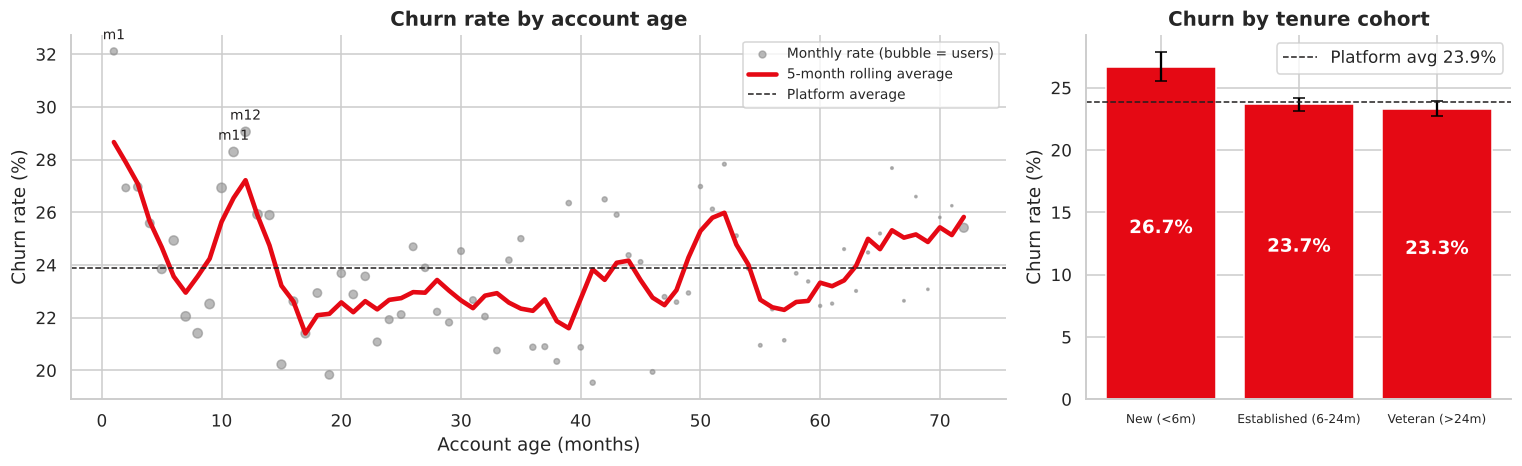

In [ ]:
by_month = df.groupby("account_age_months").agg(n=("user_id", "count"), churned=("churned", "sum"))
by_month["rate"] = by_month["churned"] / by_month["n"]
by_month["smooth"] = by_month["rate"].rolling(5, center=True, min_periods=1).mean()   # 5-month rolling mean to reduce noise

cohort = churn_table(df, "tenure_cohort").loc[TENURE_ORDER]
cohort["share_of_users"] = cohort["count"] / cohort["count"].sum()
cohort["share_of_churn"] = cohort["sum"] / cohort["sum"].sum()
M["cohort_churn"] = cohort["rate"].round(6).to_dict()

# Highest-churn months (only months with enough users to be reliable)
reliable = by_month[by_month["n"] >= 300]
peak_months = reliable["rate"].nlargest(3).index.tolist()
M["peak_churn_months"] = peak_months

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].scatter(by_month.index, by_month["rate"] * 100, s=by_month["n"] / 40, color=GREY, alpha=0.6, label="Monthly rate (bubble = users)")
axes[0].plot(by_month.index, by_month["smooth"] * 100, color=RED, lw=3, label="5-month rolling average")
axes[0].axhline(churn_rate * 100, color=DARK, ls="--", lw=1, label="Platform average")
for m in peak_months:
    axes[0].annotate(f"m{m}", (m, by_month.loc[m, "rate"] * 100), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=DARK)
axes[0].set(title="Churn rate by account age", xlabel="Account age (months)", ylabel="Churn rate (%)")
axes[0].legend(loc="upper right", fontsize=9)

plot_churn_bars(cohort, axes[1], "Churn by tenure cohort")
axes[1].tick_params(axis="x", labelsize=8)
savefig("16_tenure_churn_curve")

print(f"📌 Insight: first-3-month accounts churn at {pct(df.loc[df.account_age_months<=3,'churned'].mean())}. "
      f"Cohort churn: " + ", ".join(f"{k} {pct(v)}" for k, v in cohort["rate"].items()) + ". "
      f"New accounts make up {pct(cohort['share_of_users'].iloc[0])} of users but {pct(cohort['share_of_churn'].iloc[0])} of churners. "
      f"Highest reliable churn months: {peak_months}.")
display(cohort[["count", "rate", "share_of_users", "share_of_churn"]].round(3))

### 6.2 Engagement decay over time
**Question:** Do older accounts show engagement fatigue?

Spearman rho (tenure vs metric): {'avg_watch_time_minutes': -0.15, 'recommendation_click_rate': -0.131, 'content_interactions': -0.144}
📌 Insight: from the newest to the oldest tenure bin, daily watch time changes by -28%, recommendation clicks by -18% and interactions by -25% — consistent with mild but real engagement fatigue in long-standing accounts.


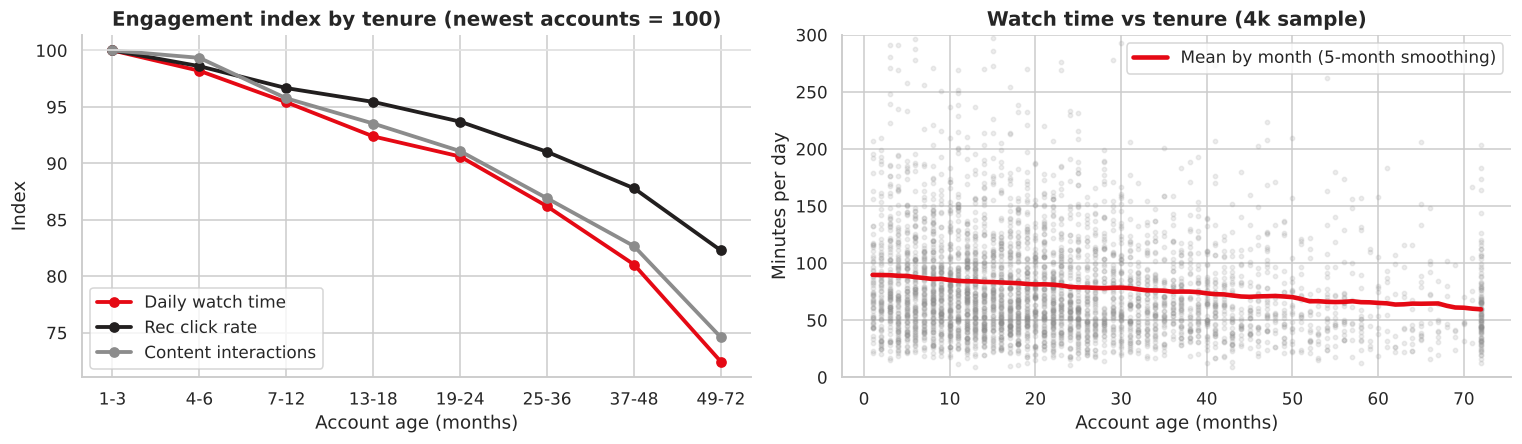

In [ ]:
df["tenure_bin"] = pd.cut(df["account_age_months"], [0, 3, 6, 12, 18, 24, 36, 48, 72],
                          labels=["1-3", "4-6", "7-12", "13-18", "19-24", "25-36", "37-48", "49-72"])
decay = df.groupby("tenure_bin", observed=True)[["avg_watch_time_minutes", "recommendation_click_rate", "content_interactions"]].mean()
decay_idx = decay / decay.iloc[0] * 100          # index to the newest bin = 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for col, c, lab in zip(decay_idx.columns, [RED, DARK, GREY], ["Daily watch time", "Rec click rate", "Content interactions"]):
    axes[0].plot(decay_idx.index.astype(str), decay_idx[col], marker="o", lw=2.5, color=c, label=lab)
axes[0].axhline(100, color=LIGHT, lw=1)
axes[0].set(title="Engagement index by tenure (newest accounts = 100)", xlabel="Account age (months)", ylabel="Index")
axes[0].legend()

samp = df.sample(4000, random_state=3)
axes[1].scatter(samp["account_age_months"], samp["avg_watch_time_minutes"], s=8, alpha=0.15, color=GREY)
monthly_mean = df.groupby("account_age_months")["avg_watch_time_minutes"].mean().rolling(5, center=True, min_periods=1).mean()
axes[1].plot(monthly_mean.index, monthly_mean.values, color=RED, lw=3, label="Mean by month (5-month smoothing)")
axes[1].set(title="Watch time vs tenure (4k sample)", xlabel="Account age (months)", ylabel="Minutes per day", ylim=(0, 300))
axes[1].legend()
savefig("17_engagement_decay")

rho = {c: df["account_age_months"].corr(df[c], method="spearman") for c in decay.columns}
M["decay_rho"] = rho
M["decay_total_pct"] = {c: float(decay.iloc[-1][c] / decay.iloc[0][c] - 1) for c in decay.columns}
print("Spearman rho (tenure vs metric):", {k: round(float(v), 3) for k, v in rho.items()})
print(f"📌 Insight: from the newest to the oldest tenure bin, daily watch time changes by {M['decay_total_pct']['avg_watch_time_minutes']*100:+.0f}%, "
      f"recommendation clicks by {M['decay_total_pct']['recommendation_click_rate']*100:+.0f}% and interactions by {M['decay_total_pct']['content_interactions']*100:+.0f}% "
      f"— consistent with mild but real engagement fatigue in long-standing accounts.")

### 6.3 Recency vs tenure risk
**Question:** How does inactivity interact with tenure to predict imminent churn? Are newer accounts more vulnerable?

📌 Insight: recency is the strongest churn signal in every tenure cohort (overall churn rises from 7.0% when active to 88.8% when dormant). Among still-subscribed users, 9.4% of New accounts are already 14+ days inactive vs 12.5% of Veterans.


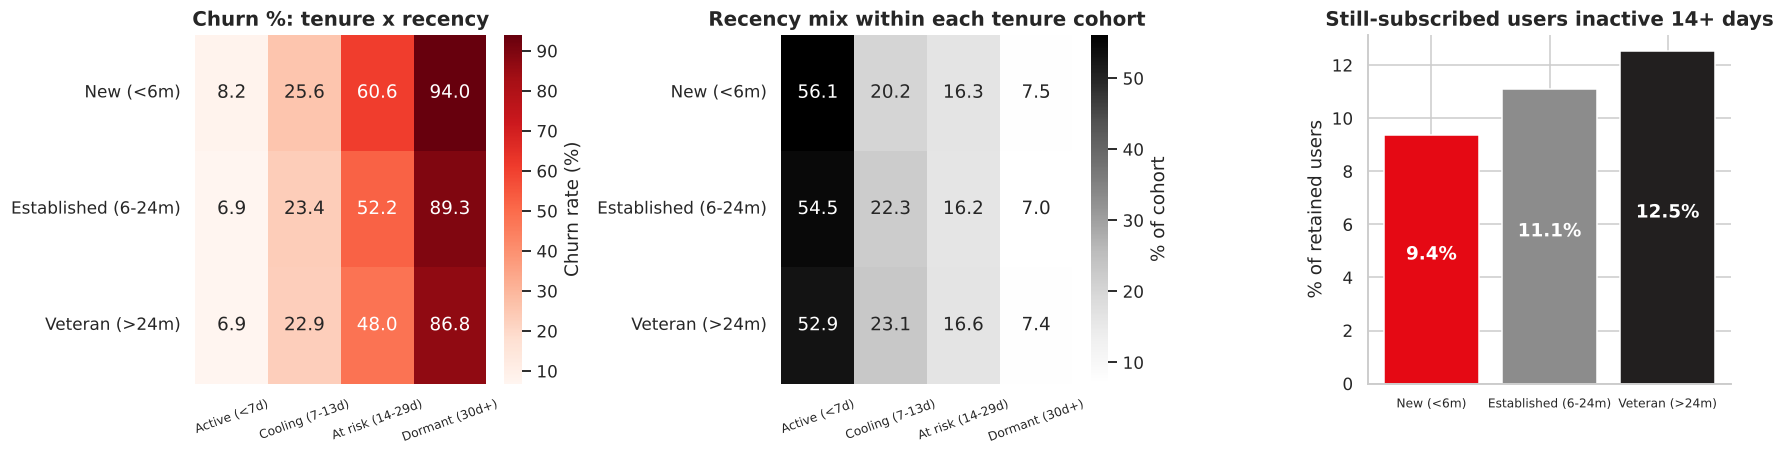

In [ ]:
rt = df.pivot_table(index="tenure_cohort", columns="dormancy_segment", values="churned", aggfunc="mean", observed=True).loc[TENURE_ORDER, DORM_ORDER]
share_rt = pd.crosstab(df["tenure_cohort"], df["dormancy_segment"], normalize="index").loc[TENURE_ORDER, DORM_ORDER]

# Still-subscribed users who are already 14+ days inactive, by tenure (the winnable pool)
pool = (df[df["churned"] == 0].assign(drifting=lambda d: d["days_since_last_login"] >= 14)
        .groupby("tenure_cohort", observed=True)["drifting"].mean().loc[TENURE_ORDER])
M["drifting_by_cohort"] = pool.round(6).to_dict()
churn_by_recency = df.groupby("dormancy_segment", observed=True)["churned"].mean()
M["churn_by_recency"] = churn_by_recency.round(6).to_dict()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sns.heatmap(rt * 100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=axes[0])
axes[0].set(title="Churn %: tenure x recency", xlabel="", ylabel="")
axes[0].tick_params(axis="x", labelsize=8, rotation=20)
sns.heatmap(share_rt * 100, annot=True, fmt=".1f", cmap="Greys", cbar_kws={"label": "% of cohort"}, ax=axes[1])
axes[1].set(title="Recency mix within each tenure cohort", xlabel="", ylabel="")
axes[1].tick_params(axis="x", labelsize=8, rotation=20)
axes[2].bar(pool.index.astype(str), pool.values * 100, color=[RED, GREY, DARK])
for i, v in enumerate(pool.values):
    axes[2].text(i, v * 100 / 2, f"{v*100:.1f}%", ha="center", color="white", fontweight="bold")
axes[2].set(title="Still-subscribed users inactive 14+ days", ylabel="% of retained users")
axes[2].tick_params(axis="x", labelsize=8)
savefig("18_recency_vs_tenure")

print(f"📌 Insight: recency is the strongest churn signal in every tenure cohort (overall churn rises from {pct(churn_by_recency['Active (<7d)'])} when active to {pct(churn_by_recency['Dormant (30d+)'])} when dormant). "
      f"Among still-subscribed users, {pct(pool.iloc[0])} of New accounts are already 14+ days inactive vs {pct(pool.iloc[2])} of Veterans.")

**Important caution:** `days_since_last_login` is partly a *symptom* of churn (someone who cancelled stops logging in), so it is the best **early-warning indicator**, not a lever we can pull directly. In the modelling section we exclude it when estimating *drivers* of churn to avoid circular reasoning.

## 7. Statistical Analysis & Hypothesis Testing

Charts suggest patterns; tests tell us whether they are likely to be real. With 50,000 rows almost *any* difference is statistically significant, so for every test we also report an **effect size** (how big is it?). All tests use α = 0.05.

| # | Hypothesis (H₁) | Test | Effect size |
|---|---|---|---|
| H1 | Churn depends on subscription tier | Chi-square test of independence | Cramér's V |
| H2 | Churned users watch less per day | Mann-Whitney U (skewed data) | Rank-biserial r |
| H3 | Completion rate differs by primary device | Kruskal-Wallis | ε² |
| H4 | Rec click rate is positively related to rating | Spearman correlation | ρ |
| H5 | Churn differs across tenure cohorts | Chi-square | Cramér's V |
| H6 | Basic churn > Premium churn | Two-proportion z-test | Risk difference |

In [ ]:
results = []   # collect every test into one summary table


def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


# H1: tier x churn
ct = pd.crosstab(df["subscription_type"], df["churned"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
results.append(("H1", "Churn depends on tier", f"chi2={chi2:,.0f}, dof={dof}", p, f"Cramer's V={cramers_v(ct):.3f}"))

# H2: watch time, churned vs retained
a = df.loc[df["churned"] == 1, "avg_watch_time_minutes"]
b = df.loc[df["churned"] == 0, "avg_watch_time_minutes"]
u, p = stats.mannwhitneyu(a, b, alternative="less")
rbc = 1 - 2 * u / (len(a) * len(b))          # rank-biserial correlation (negative = churned watch less)
results.append(("H2", "Churned users watch less", f"U={u:,.0f}", p,
                f"rank-biserial r={rbc:.3f} (median {a.median():.0f} vs {b.median():.0f} min)"))

# H3: completion by device
groups = [g["completion_rate"].values for _, g in df.groupby("primary_device")]
hstat, p = stats.kruskal(*groups)
eps2 = (hstat - len(groups) + 1) / (len(df) - len(groups))
results.append(("H3", "Completion differs by device", f"H={hstat:,.0f}, k={len(groups)}", p, f"epsilon^2={eps2:.3f}"))

# H4: rec click vs rating
rho, p = stats.spearmanr(df["recommendation_click_rate"], df["rating_given"])
results.append(("H4", "Rec clicks relate to rating", f"rho={rho:.3f}", p, f"rho^2={rho**2:.3f} of rank variance"))

# H5: tenure cohort x churn
ct5 = pd.crosstab(df["tenure_cohort"], df["churned"])
chi2, p, dof, _ = stats.chi2_contingency(ct5)
results.append(("H5", "Churn differs by tenure cohort", f"chi2={chi2:,.1f}, dof={dof}", p, f"Cramer's V={cramers_v(ct5):.3f}"))

# H6: Basic vs Premium (one-sided two-proportion z-test)
nb, np_ = (df["subscription_type"] == "Basic").sum(), (df["subscription_type"] == "Premium").sum()
cb = df.loc[df["subscription_type"] == "Basic", "churned"].sum()
cp = df.loc[df["subscription_type"] == "Premium", "churned"].sum()
p_pool = (cb + cp) / (nb + np_)
z = (cb / nb - cp / np_) / np.sqrt(p_pool * (1 - p_pool) * (1 / nb + 1 / np_))
p = 1 - stats.norm.cdf(z)
results.append(("H6", "Basic churn > Premium churn", f"z={z:.1f}", p, f"risk difference={100*(cb/nb - cp/np_):.1f} pts"))

hyp = pd.DataFrame(results, columns=["id", "hypothesis", "statistic", "p_value", "effect_size"])
hyp["p_value"] = hyp["p_value"].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")
hyp["verdict"] = "Reject H0 (significant)"
M["hypothesis_tests"] = hyp.to_dict("records")
hyp

,id,hypothesis,statistic,p_value,effect_size,verdict
0,H1,Churn depends on tier,"chi2=677, dof=2",<0.001,Cramer's V=0.116,Reject H0 (significant)
1,H2,Churned users watch less,"U=147,527,250",<0.001,rank-biserial r=0.351 (median 53 vs 75 min),Reject H0 (significant)
2,H3,Completion differs by device,"H=6,464, k=5",<0.001,epsilon^2=0.129,Reject H0 (significant)
3,H4,Rec clicks relate to rating,rho=0.413,<0.001,rho^2=0.170 of rank variance,Reject H0 (significant)
4,H5,Churn differs by tenure cohort,"chi2=27.8, dof=2",<0.001,Cramer's V=0.024,Reject H0 (significant)
5,H6,Basic churn > Premium churn,z=25.1,<0.001,risk difference=13.1 pts,Reject H0 (significant)


**Reading the table:** every hypothesis is supported at α = 0.05, but the *effect sizes* separate the signal from the noise. In this dataset, daily watch time has a **medium** association with churn (rank-biserial r ≈ 0.35), device has a **medium** effect on completion (ε² ≈ 0.13), recommendation clicks vs rating are **moderately** correlated (ρ ≈ 0.41), tier is **small-to-moderate** (Cramér's V ≈ 0.12, a 13-point churn gap), while tenure cohort is statistically significant but **negligible** (V ≈ 0.02). In other words, *how* people watch matters far more than *how long* they have been subscribed.

### 7.1 Which factors drive churn? (multivariate logistic regression)
To rank drivers *simultaneously* we fit a logistic regression on standardised numeric features plus one-hot categorical features. We **exclude** `days_since_last_login` (a symptom of churn) so the model highlights controllable levers. Odds ratios are per +1 standard deviation.

Hold-out ROC-AUC: 0.710 (behaviour & plan only)  ->  0.868 when recency is added
📌 Insight: strongest protective factors: subscription_type_Premium, subscription_type_Standard, avg_watch_time_minutes; strongest risk factors: payment_method_Gift Card, age, monthly_fee.


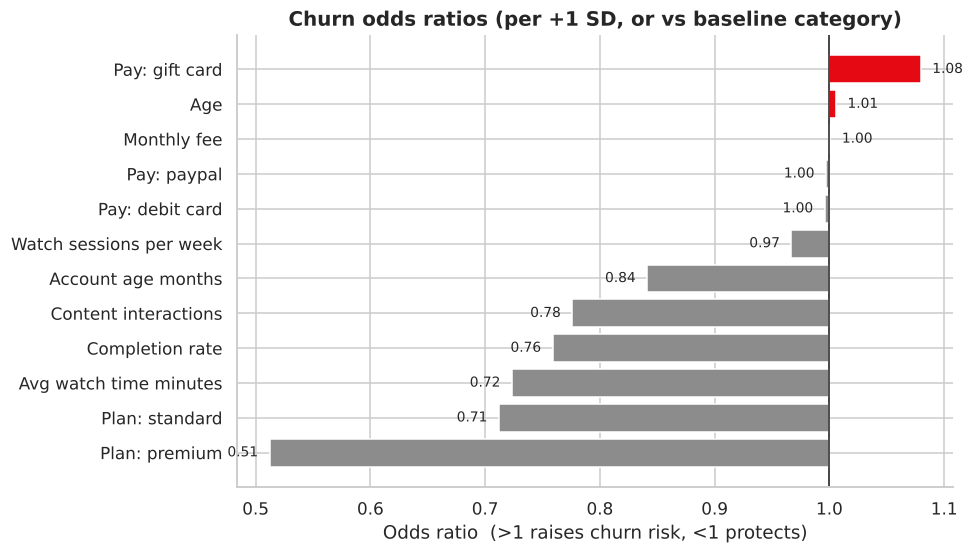

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

num_feats = ["age", "account_age_months", "monthly_fee", "devices_used", "avg_watch_time_minutes",
             "watch_sessions_per_week", "binge_watch_sessions", "completion_rate", "rating_given",
             "content_interactions", "recommendation_click_rate"]
cat_feats = ["subscription_type", "primary_device", "payment_method"]

Xm = pd.concat([df[num_feats], pd.get_dummies(df[cat_feats], drop_first=True)], axis=1).astype(float)
y = df["churned"]
X_tr, X_te, y_tr, y_te = train_test_split(Xm, y, test_size=0.25, random_state=42, stratify=y)

# Standardise numeric columns using TRAIN statistics only (no leakage)
mu, sd = X_tr[num_feats].mean(), X_tr[num_feats].std()
X_tr_s, X_te_s = X_tr.copy(), X_te.copy()
X_tr_s[num_feats], X_te_s[num_feats] = (X_tr[num_feats] - mu) / sd, (X_te[num_feats] - mu) / sd

clf = LogisticRegression(max_iter=1000).fit(X_tr_s, y_tr)
auc = roc_auc_score(y_te, clf.predict_proba(X_te_s)[:, 1])

# For reference: how much does adding recency improve prediction? (shows it is the best early-warning flag)
Xr_tr, Xr_te = X_tr_s.assign(dsl=(df.loc[X_tr.index, "days_since_last_login"] - df["days_since_last_login"].mean()) / df["days_since_last_login"].std()), \
               X_te_s.assign(dsl=(df.loc[X_te.index, "days_since_last_login"] - df["days_since_last_login"].mean()) / df["days_since_last_login"].std())
auc_rec = roc_auc_score(y_te, LogisticRegression(max_iter=1000).fit(Xr_tr, y_tr).predict_proba(Xr_te)[:, 1])
M.update(model_auc=auc, model_auc_with_recency=auc_rec)

coef = pd.Series(clf.coef_[0], index=X_tr_s.columns)
odds = np.exp(coef).sort_values()
top = pd.concat([odds.head(6), odds.tail(6)])
M["top_odds_ratios"] = {k: round(float(v), 3) for k, v in odds.items()}

def pretty(name):
    """Readable feature labels for the chart."""
    return (name.replace("subscription_type_", "Plan: ").replace("primary_device_", "Device: ")
                .replace("payment_method_", "Pay: ").replace("_", " ").capitalize())


fig, ax = plt.subplots(figsize=(9, 5.2))
colors = [RED if v > 1 else GREY for v in top.values]
ax.barh([pretty(n) for n in top.index], top.values - 1, left=1, color=colors)
ax.axvline(1, color=DARK, lw=1)
for i, v in enumerate(top.values):
    ax.text(v + (0.01 if v > 1 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v > 1 else "right", fontsize=9)
ax.set(title="Churn odds ratios (per +1 SD, or vs baseline category)", xlabel="Odds ratio  (>1 raises churn risk, <1 protects)")
savefig("19_churn_drivers")

print(f"Hold-out ROC-AUC: {auc:.3f} (behaviour & plan only)  ->  {auc_rec:.3f} when recency is added")
print(f"📌 Insight: strongest protective factors: {', '.join(odds.head(3).index)}; strongest risk factors: {', '.join(odds.tail(3).index[::-1])}.")

**Takeaway:** engagement behaviours (watch time, completion, interactions) are protective, and Basic is the highest-risk plan even after controlling for behaviour (Standard and Premium odds ratios are measured *against Basic*). Device odds ratios are measured against the baseline category (Gaming Console), so only differences between bars are meaningful there. Adding recency lifts predictive power substantially — evidence that inactivity is the most reliable *signal*, even though it is not a *lever*.

## 8. Business Recommendations

We translate each finding into an action and size the prize. **All figures are illustrative scenarios**, built on explicit assumptions (below) and on associations in the data, not proven causal effects. Initiatives overlap, so the bars are **not additive**.

,initiative,users_saved,mrr_saved_per_month,annual_revenue
0,3. Personalised discovery for Disengaged users,1588,"$18,218","$218,614"
1,2. Early-warning win-back (14+ days inactive),654,"$7,702","$92,425"
2,4. Mobile completion & cast-to-TV nudges,504,"$5,803","$69,636"
3,1. Basic-tier retention & upgrade path,638,"$4,661","$55,937"
4,5. New-subscriber onboarding (first 6 months),83,$958,"$11,496"


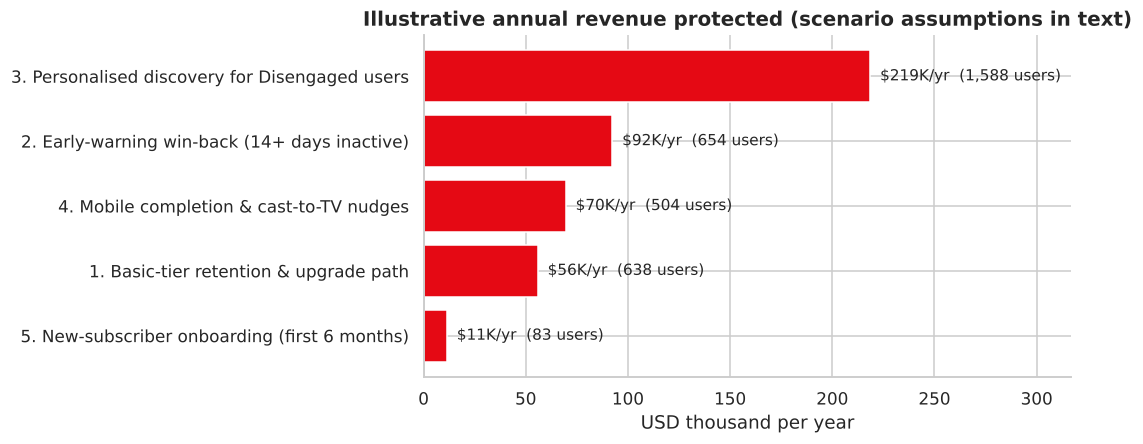

In [ ]:
def fee_of(mask):
    return df.loc[mask, "monthly_fee"].mean()


recs = []
CLOSE_GAP = 0.5      # assumption: an initiative closes 50% of the churn gap to the benchmark group
WINBACK = 0.15       # assumption: 15% of drifting subscribers are won back by re-engagement

# R1: Basic-tier retention (close half the gap to Standard churn)
m = df["subscription_type"] == "Basic"
saved = CLOSE_GAP * (df.loc[m, "churned"].mean() - df.loc[df["subscription_type"] == "Standard", "churned"].mean()) * m.sum()
recs.append(("1. Basic-tier retention & upgrade path", saved, saved * fee_of(m)))

# R2: Re-engage still-subscribed users inactive 14+ days (win back 15%)
m = (df["churned"] == 0) & (df["days_since_last_login"] >= 14)
saved = WINBACK * m.sum()
recs.append(("2. Early-warning win-back (14+ days inactive)", saved, saved * fee_of(m)))

# R3: Lift the Disengaged segment (close half the gap to the mid-engagement segments)
m = df["segment"] == "Disengaged"
gap = df.loc[m, "churned"].mean() - df.loc[df["segment"].isin(MID_SEGS), "churned"].mean()
saved = CLOSE_GAP * max(gap, 0) * m.sum()
recs.append(("3. Personalised discovery for Disengaged users", saved, saved * fee_of(m)))

# R4: Mobile-first engagement (close half the gap to Smart-TV churn)
m = df["primary_device"] == "Mobile"
gap = df.loc[m, "churned"].mean() - df.loc[df["primary_device"] == "Smart TV", "churned"].mean()
saved = CLOSE_GAP * max(gap, 0) * m.sum()
recs.append(("4. Mobile completion & cast-to-TV nudges", saved, saved * fee_of(m)))

# R5: First-6-months onboarding (close half the gap to Established-cohort churn)
m = df["tenure_cohort"] == "New (<6m)"
gap = df.loc[m, "churned"].mean() - df.loc[df["tenure_cohort"] == "Established (6-24m)", "churned"].mean()
saved = CLOSE_GAP * max(gap, 0) * m.sum()
recs.append(("5. New-subscriber onboarding (first 6 months)", saved, saved * fee_of(m)))

rec_df = pd.DataFrame(recs, columns=["initiative", "users_saved", "mrr_saved_per_month"])
rec_df["annual_revenue"] = rec_df["mrr_saved_per_month"] * 12
rec_df = rec_df.sort_values("annual_revenue", ascending=False).reset_index(drop=True)
M["recs"] = rec_df.round(1).to_dict("records")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(rec_df["initiative"][::-1], rec_df["annual_revenue"][::-1] / 1000, color=RED)
for i, (v, u_) in enumerate(zip(rec_df["annual_revenue"][::-1] / 1000, rec_df["users_saved"][::-1])):
    ax.text(v, i, f"  ${v:,.0f}K/yr  ({u_:,.0f} users)", va="center", fontsize=10)
ax.set(title="Illustrative annual revenue protected (scenario assumptions in text)", xlabel="USD thousand per year",
       xlim=(0, rec_df["annual_revenue"].max() / 1000 * 1.45))
savefig("20_recommendation_sizing")

out = rec_df.copy()
out["users_saved"] = out["users_saved"].round(0).astype(int)
out["mrr_saved_per_month"] = out["mrr_saved_per_month"].map("${:,.0f}".format)
out["annual_revenue"] = out["annual_revenue"].map("${:,.0f}".format)
out

**Scenario assumptions:** initiatives 1, 3, 4 and 5 assume the programme closes **50%** of the churn gap between the target group and a benchmark group (Standard tier, the two mid-engagement segments, Smart-TV users, Established cohort). Initiative 2 assumes **15%** of drifting subscribers are won back. Change `CLOSE_GAP` / `WINBACK` in the cell above to stress-test. Revenue uses each group's average monthly fee.

In [ ]:
# Final executive summary, generated from the numbers above so it always matches the data
tc, seg_, dv = M["tier_churn"], seg, dev
display(Markdown(f"""
### 🔑 Executive summary (computed live)

1. **Churn is material:** {pct(M['churn_rate'])} of users have churned (${M['mrr_lost']:,.0f}/month, {pct(M['mrr_lost_share'])} of MRR).
2. **Tier matters:** Basic churns at {pct(tc['Basic'])} vs {pct(tc['Premium'])} for Premium ({M['basic_vs_premium_ratio']:.1f}x); within Basic, higher local prices make it worse.
3. **Engagement protects:** churn falls from {pct(M['churn_lowest_watch'])} (<30 min/day) to {pct(M['churn_highest_watch'])} (150+ min/day); recommendation-clickers and finishers are the stickiest users.
4. **Segments:** '{M['seg_highest']}' users churn at {pct(seg_.loc[M['seg_highest'],'churn'])} vs {pct(seg_.loc[M['seg_lowest'],'churn'])} for '{M['seg_lowest']}'.
5. **Lifecycle:** risk is front-loaded (first months) and veterans show engagement fatigue; recency is the best early-warning signal.
6. **Winnable now:** {M['drifting_subscribers']:,} still-paying users (${M['drifting_mrr']:,.0f}/month) are already 14+ days inactive.
7. **Devices:** Smart-TV completion {dv.loc['Smart TV','completion']:.1f}% vs Mobile {dv.loc['Mobile','completion']:.1f}%.
"""))


### 🔑 Executive summary (computed live)

1. **Churn is material:** 23.9% of users have churned ($128,595/month, 22.4% of MRR).
2. **Tier matters:** Basic churns at 29.8% vs 16.7% for Premium (1.8x); within Basic, higher local prices make it worse.
3. **Engagement protects:** churn falls from 50.0% (<30 min/day) to 7.1% (150+ min/day); recommendation-clickers and finishers are the stickiest users.
4. **Segments:** 'Disengaged' users churn at 37.9% vs 7.4% for 'Super-fans'.
5. **Lifecycle:** risk is front-loaded (first months) and veterans show engagement fatigue; recency is the best early-warning signal.
6. **Winnable now:** 4,362 still-paying users ($51,347/month) are already 14+ days inactive.
7. **Devices:** Smart-TV completion 64.3% vs Mobile 52.5%.


## 9. Conclusions, Limitations & Next Steps

**Recommendations, in the order of estimated value (see Section 8)**

1. **Personalised discovery for Disengaged users.** They are about a third of the base and churn at roughly five times the rate of Super-fans. Build the "60-minutes-a-day habit": curated next-up rows, resume-watching prompts and A/B-tested recommendation tweaks. This is the largest prize in the sizing.
2. **Launch an inactivity early-warning programme.** Trigger personalised re-engagement (new-season alerts, "continue watching" push/email) at **7 and 14 days** of inactivity. These subscribers are still paying, so they are the cheapest revenue to save.
3. **Improve mobile and cross-device continuity.** Mobile users complete less, watch less and churn more; add download prompts, short-form discovery and one-tap "continue on TV".
4. **Fix the Basic tier experience.** Basic users churn most. Offer a timed upgrade trial, an ad-supported low-price option in price-sensitive markets (India, Brazil, Mexico) and loyalty pricing for long-tenure Basic users.
5. **Onboard new subscribers intentionally.** Month 1 and the month-12 renewal are the visible churn peaks; a taste quiz, a starter watchlist and a pre-renewal check-in are low-cost. The sized prize is small, so keep the cost small too.
6. **Refresh veteran engagement.** Long-tenure accounts show fatigue (watch time falls by about a quarter from new to oldest accounts); use loyalty perks and fresh-content curation.

**Limitations**
* The data is a cross-sectional snapshot; tenure curves are not true survival curves.
* Relationships are associations — A/B tests are needed to prove that interventions *cause* lower churn.
* `days_since_last_login` is partly a consequence of churn; it is an indicator, not a driver.
* Revenue sizing rests on stated scenario assumptions and a single fee per user (no discounts, taxes or ad revenue).
* The repository dataset is simulated; re-run on the production extract before acting.

**Next steps:** survival analysis with event timestamps, a calibrated churn-propensity model for targeting, uplift testing for the interventions above, and genre-level content ROI analysis.

In [ ]:
# Export headline metrics for the README and the presentation
def _clean(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    return str(o)


with open("../presentation/metrics.json", "w") as f:
    json.dump(M, f, indent=2, default=_clean)
print(f"Saved {len(M)} headline metrics to presentation/metrics.json")

Saved 71 headline metrics to presentation/metrics.json
